# Gene Trajectory Clustering (responsive genes: p < 0.05 only)

Builds one gene-trajectory AnnData (`traj`: rows are gene × context trajectories, columns aligned time points) from the final 8-knot tradeSeq fits of the three contexts (K562 + TNF-alpha `K562a`, K562 + LPS `K562b`, THP-1 + LPS `THP1`), characterizes each trajectory, and clusters the significant ones into dynamic modes, separately for induced and repressed genes. The figures that follow show the trajectory-shape PCA, broad and fine dynamic modes, mode proportions and their reassignment across contexts. Plotting logic lives in `chronopack.pl`; plots are written to `gene_clustering/plots/`.

**Variant of `01_GeneTrajectoryClustering.ipynb`.** Clustering is unchanged; the only difference is the *responsive* trajectories used for the mode proportions and the cross-context figures: every significant trajectory (`pvalue_1` < 0.05), without the |peak log2FC| >= 0.5 cut. Outputs go to `gene_clustering/pvalue_only/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import chronopack as cp

In [2]:
# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
root_k562a = (DATA_DIR / "k562-tnfa.hg38.rep").resolve()
root_lps = (DATA_DIR / "thp1-k562-lps.hg38.rep").resolve()

OUTPUT_DIR = (DATA_DIR / "gene_clustering" / "pvalue_only").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

## Build and characterize gene trajectories

Fitted curves are aligned onto a common time axis (time span, onset offset and THP1 time scaling per context); association statistics come from `rowData(sce)`. Descriptors (onset, peak, log2 fold change, curvature, ...) are added to `traj.obs`.

In [3]:
sce_dict = {
    "K562a": root_k562a / "intmd" / "sc-K562-1e4_to_tradeSeq.fixed" / "sce.1trajectory.nknots8.rds",
    "K562b": root_lps / "intmd" / "sc-K562_to_tradeSeq.fixed" / "sce.1trajectory.nknots8.rds",
    "THP1": root_lps / "intmd" / "sc-THP1_to_tradeSeq.fixed" / "sce.1trajectory.nknots8.rds",
}
traj = cp.tl.align_gene_trajectories(
    sce_dict,
    time_map={"K562a": 110, "K562b": 165, "THP1": 165},
    offset_map={"K562a": 0, "K562b": -68, "THP1": -10},
    scale_map={"THP1": 0.65},
)
traj = cp.tl.compute_gene_trajectory_descriptors(traj, inplace=False)
traj.write_h5ad(OUTPUT_DIR / "gene_trajectory_characterization.h5ad")
traj

[K562a] TMAX=110, scale=1, offset=0 => aligned range 0.00..110.00, resampled to 110 minute points
[K562b] TMAX=165, scale=1, offset=-68 => aligned range 0.00..97.00, resampled to 97 minute points
[THP1] TMAX=165, scale=0.65, offset=-10 => aligned range 0.40..97.25, resampled to 97 minute points
Shortest aligned end time across keys after rescaling: 97 min
Final shared aligned minute range: 1 .. 97  (n = 97 )


R callback write-console: Loading required package: SingleCellExperiment
  
R callback write-console: Loading required package: SummarizedExperiment
  
R callback write-console: Loading required package: MatrixGenerics
  
R callback write-console: Loading required package: matrixStats
  
R callback write-console: 
Attaching package: 'MatrixGenerics'

  
R callback write-console: The following objects are masked from 'package:matrixStats':

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCu

AnnData object with n_obs × n_vars = 5091 × 97
    obs: 'gene', 'cell_type', 'waldStat_1', 'meanLogFC', 'pvalue_1', 'qval_1', 't_onset', 't_peak', 'baseline_exp', 'peak_exp', 'peak_dlogexp', 'peak_dexp', 'peak_log2fc', 'auc_norm', 'owp', 'owp_ddt', 'mean_curv', 'max_curv', 'mean_turn', 'max_turn'
    var: 'time'
    uns: 'chronopack'

## Cluster dynamic modes

Significant trajectories (`pvalue_1` < 0.05) are split into induced (peak log2 fold change > 0) and repressed (< 0). Each set is clustered for every candidate k, with features scaled against all significant trajectories. Broad modes use k = 3; fine modes use the k with the highest elbow score.

In [4]:
PVALUE_THRESHOLD = 0.05
ALPHA = 0.1
K_GRID = range(2, 101)
BROAD_K = 3

sig = traj[traj.obs["pvalue_1"] < PVALUE_THRESHOLD].copy()
induced = sig[sig.obs["peak_log2fc"] > 0].copy()
repressed = sig[sig.obs["peak_log2fc"] < 0].copy()
{"significant": sig.n_obs, "induced": induced.n_obs, "repressed": repressed.n_obs}

{'significant': 5091, 'induced': 2424, 'repressed': 2667}

### Induced

In [5]:
induced_clust = cp.tl.cluster_gene_trajectories(induced, k=K_GRID, reference=sig, alpha=ALPHA)
induced_clust.metrics.to_csv(OUTPUT_DIR / "cluster_metrics.induced.csv", index=False)

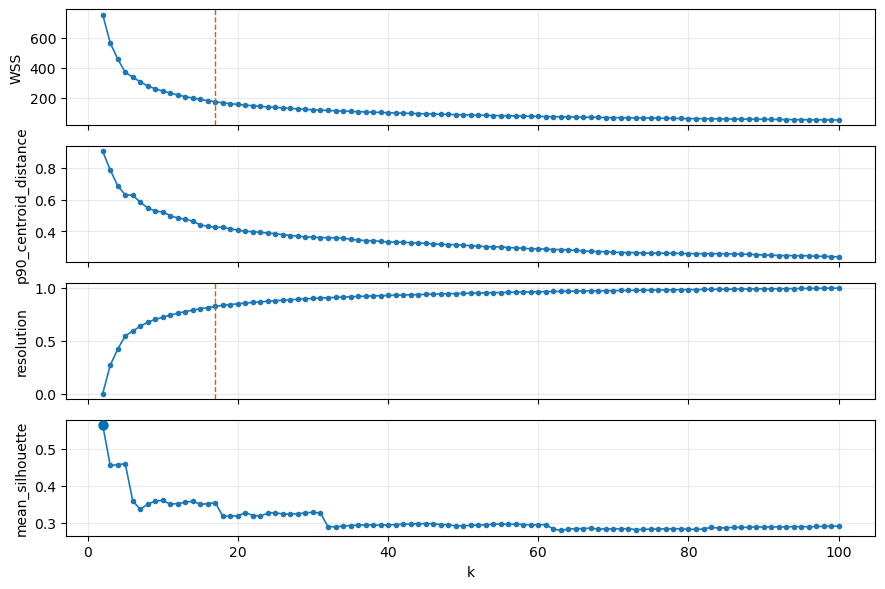

In [6]:
cp.pl.clustering_metrics(induced_clust, output=OUTPUT_DIR / "cluster_metric_selection.induced.png")
plt.show()

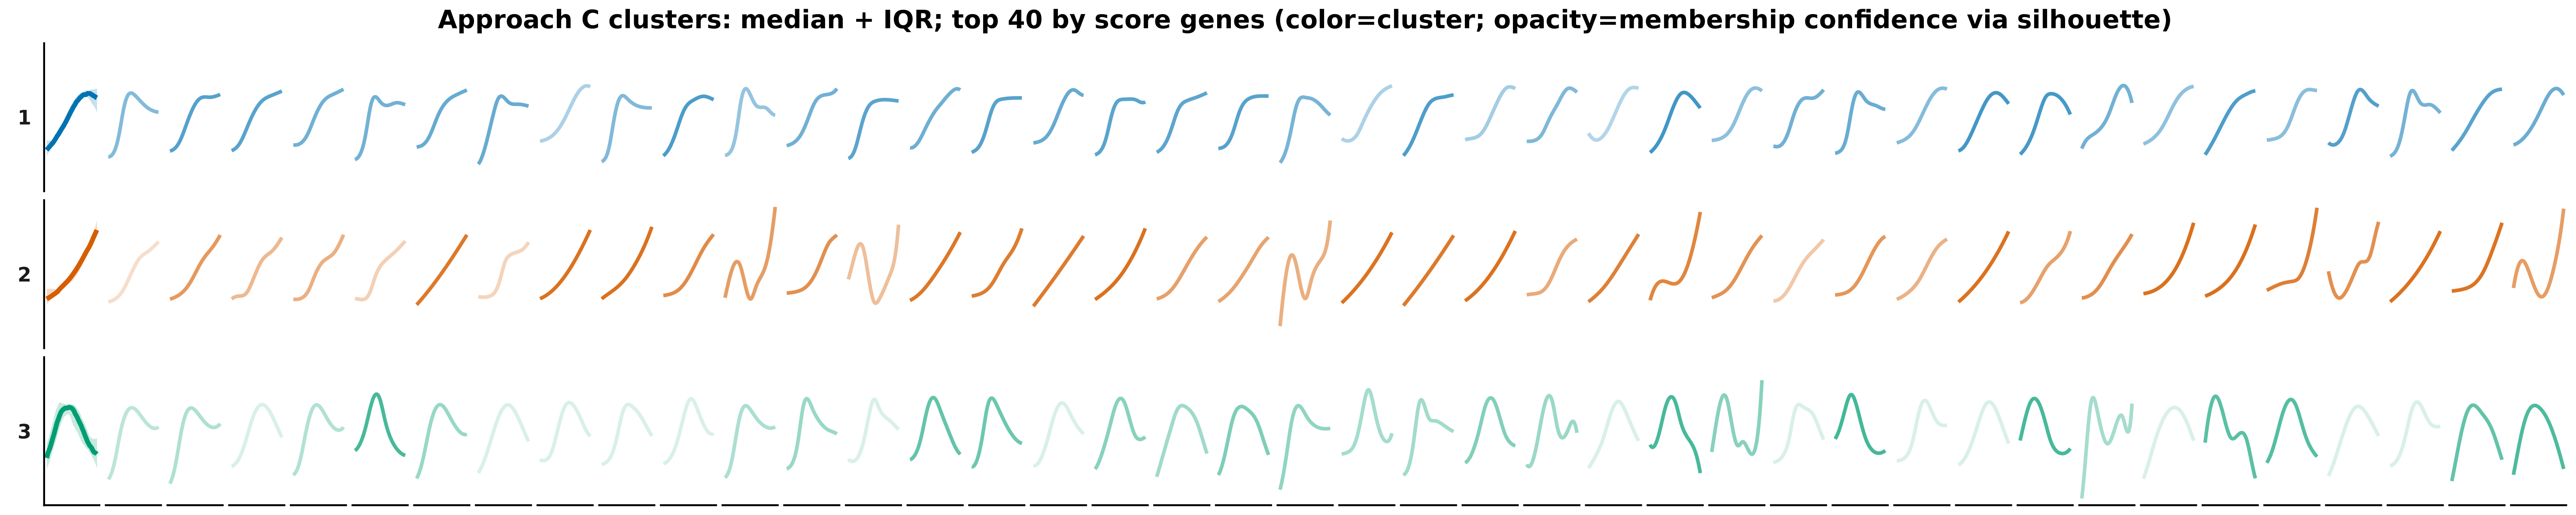

In [7]:
# Prospective broad modes (k = BROAD_K): per cluster the median + IQR, then the top trajectories
# by Wald statistic (opacity = silhouette width).
cp.pl.cluster_medoids_and_top_genes(
    induced,
    induced_clust.assignments[BROAD_K],
    features=induced_clust.features,
    seed=10,
    top_n=40,
    show_sil_text=False,
    show_median_iqr=True,
    output=OUTPUT_DIR / "broad_cluster_medoids.induced.png",
    width=20,
    height=4,
)

In [8]:
# Fine modes: the k with the highest elbow score; broad modes: BROAD_K.
induced_fine_k = int(induced_clust.metrics.loc[induced_clust.metrics["elbow_score"].idxmax(), "k"])
induced_fine_k

17

In [9]:
traj.obs["cluster_broad_induced"] = induced_clust.assignments[BROAD_K].astype(str).map({"1": "impulse-up_1", "2": "trend-up", "3": "impulse-up_2"})
traj.obs["cluster_dist_broad_induced"] = induced_clust.centroid_distances[BROAD_K]
traj.obs["cluster_fine_induced"] = induced_clust.assignments[induced_fine_k].astype(str)
traj.obs["cluster_dist_fine_induced"] = induced_clust.centroid_distances[induced_fine_k]
traj.obs.loc[induced.obs_names, "cluster_broad_induced"].value_counts()

cluster_broad_induced
trend-up        1478
impulse-up_2     474
impulse-up_1     472
Name: count, dtype: int64

### Repressed

In [10]:
repressed_clust = cp.tl.cluster_gene_trajectories(repressed, k=K_GRID, reference=sig, alpha=ALPHA)
repressed_clust.metrics.to_csv(OUTPUT_DIR / "cluster_metrics.repressed.csv", index=False)

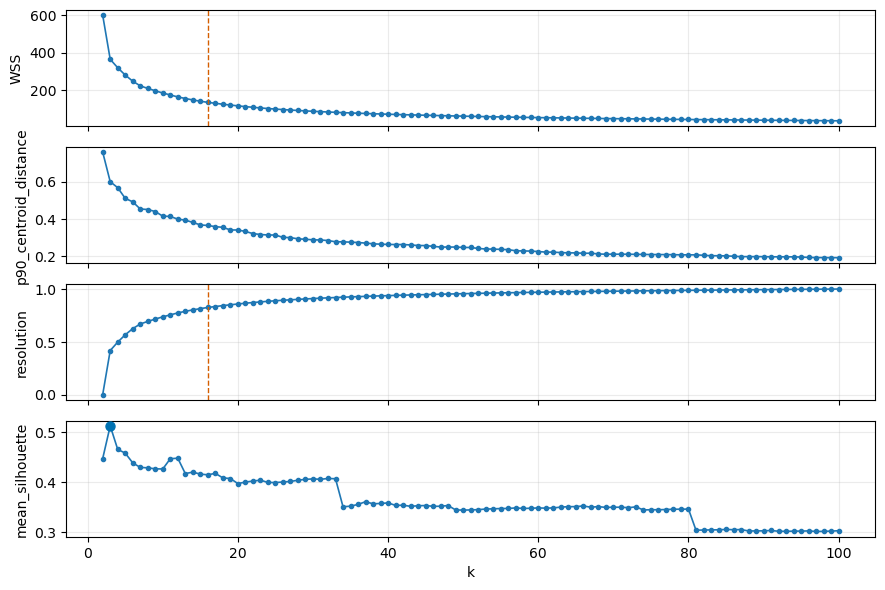

In [11]:
cp.pl.clustering_metrics(repressed_clust, output=OUTPUT_DIR / "cluster_metric_selection.repressed.png")
plt.show()

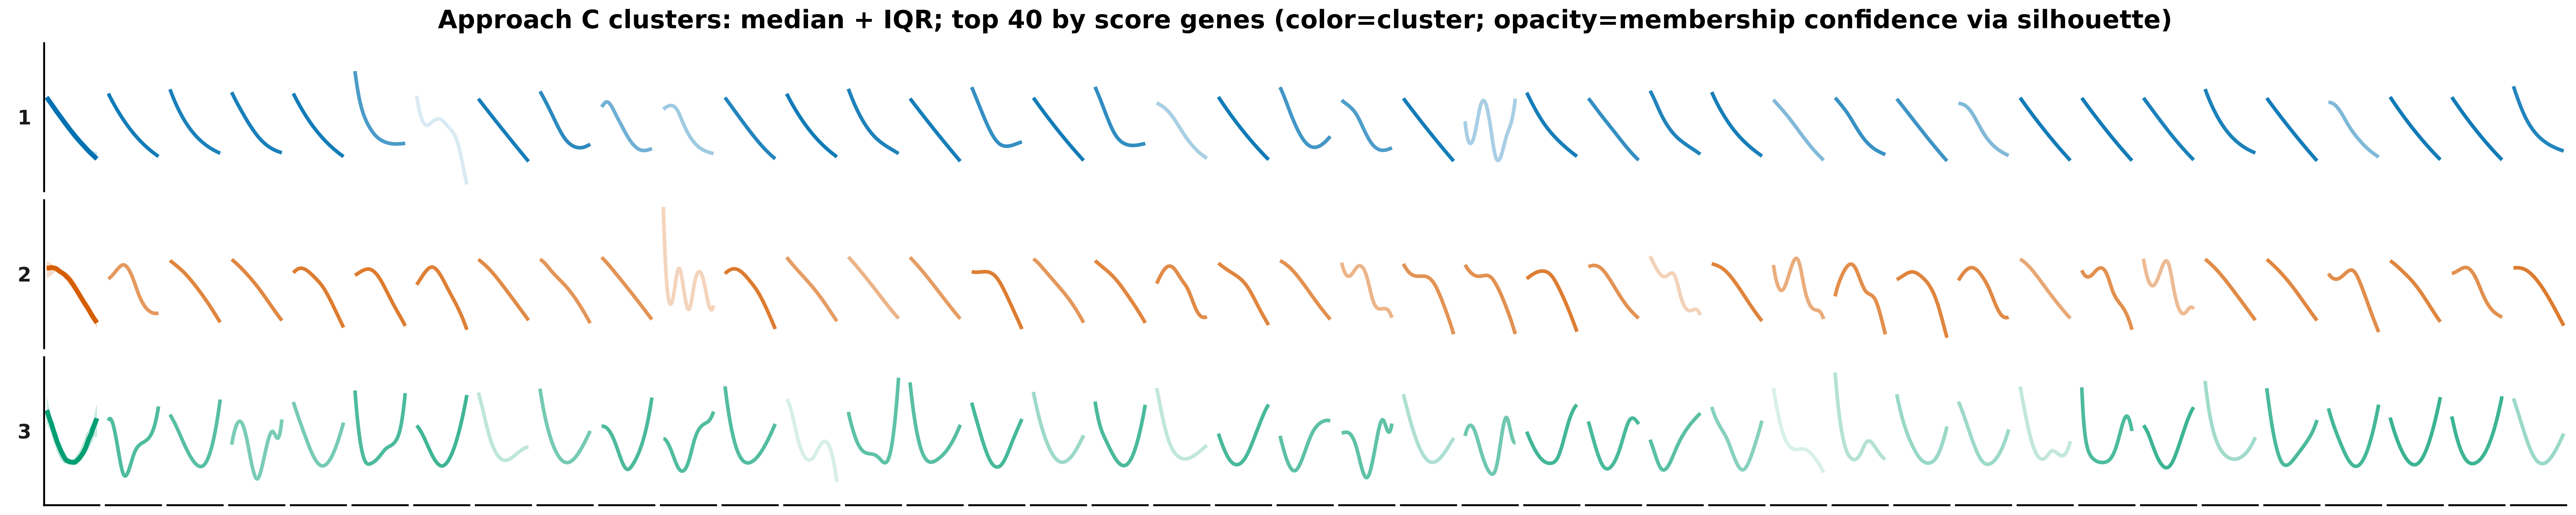

In [12]:
# Prospective broad modes (k = BROAD_K): per cluster the median + IQR, then the top trajectories
# by Wald statistic (opacity = silhouette width).
cp.pl.cluster_medoids_and_top_genes(
    repressed,
    repressed_clust.assignments[BROAD_K],
    features=repressed_clust.features,
    seed=10,
    top_n=40,
    show_sil_text=False,
    show_median_iqr=True,
    output=OUTPUT_DIR / "broad_cluster_medoids.repressed.png",
    width=20,
    height=4,
)

In [13]:
# Fine modes: the k with the highest elbow score; broad modes: BROAD_K.
repressed_fine_k = int(repressed_clust.metrics.loc[repressed_clust.metrics["elbow_score"].idxmax(), "k"])
repressed_fine_k

16

In [14]:
traj.obs["cluster_broad_repressed"] = repressed_clust.assignments[BROAD_K].astype(str).map({"1": "trend-down_1", "2": "trend-down_2", "3": "transient-down"})
traj.obs["cluster_dist_broad_repressed"] = repressed_clust.centroid_distances[BROAD_K]
traj.obs["cluster_fine_repressed"] = repressed_clust.assignments[repressed_fine_k].astype(str)
traj.obs["cluster_dist_fine_repressed"] = repressed_clust.centroid_distances[repressed_fine_k]
traj.obs.loc[repressed.obs_names, "cluster_broad_repressed"].value_counts()

cluster_broad_repressed
trend-down_1      1521
trend-down_2       897
transient-down     249
Name: count, dtype: int64

## Combine modes

Trajectories outside a set keep the label `-1`. `broad_cluster` takes the induced broad mode, or the repressed one for repressed trajectories. The PCA of trajectory shapes used for clustering is stored in `traj.obsm["X_pca"]` (first 4 components), the clustering features (scaled shape and derivative) in `traj.obsm["X_cluster_features"]`.

In [15]:
for col in ["cluster_broad_induced", "cluster_fine_induced", "cluster_broad_repressed", "cluster_fine_repressed"]:
    traj.obs[col] = traj.obs[col].fillna("-1").astype(str)

traj.obs["broad_cluster"] = traj.obs["cluster_broad_induced"].where(
    traj.obs["cluster_broad_induced"] != "-1", traj.obs["cluster_broad_repressed"]
)
traj.obs["cluster_dist_broad"] = traj.obs["cluster_dist_broad_induced"].combine_first(traj.obs["cluster_dist_broad_repressed"])
traj.obs["cluster_dist_fine"] = traj.obs["cluster_dist_fine_induced"].combine_first(traj.obs["cluster_dist_fine_repressed"])

# Both clusterings share one PCA of trajectory shapes, fitted on all significant trajectories (the reference).
traj.obsm["X_pca"] = induced_clust.pca.iloc[:, :4].reindex(traj.obs_names).to_numpy()
# The joint shape + derivative features distances were computed on (medoid plots below).
features = pd.concat([induced_clust.features, repressed_clust.features])
traj.obsm["X_cluster_features"] = features.reindex(traj.obs_names).to_numpy()

traj.write_h5ad(OUTPUT_DIR / "gene_trajectory_clusters.h5ad")
traj.obs["broad_cluster"].value_counts()

broad_cluster
trend-down_1      1521
trend-up          1478
trend-down_2       897
impulse-up_2       474
impulse-up_1       472
transient-down     249
Name: count, dtype: int64

## Trajectory shape PCA

First two components of the PCA of trajectory shapes used for clustering, coloured by broad dynamic mode.

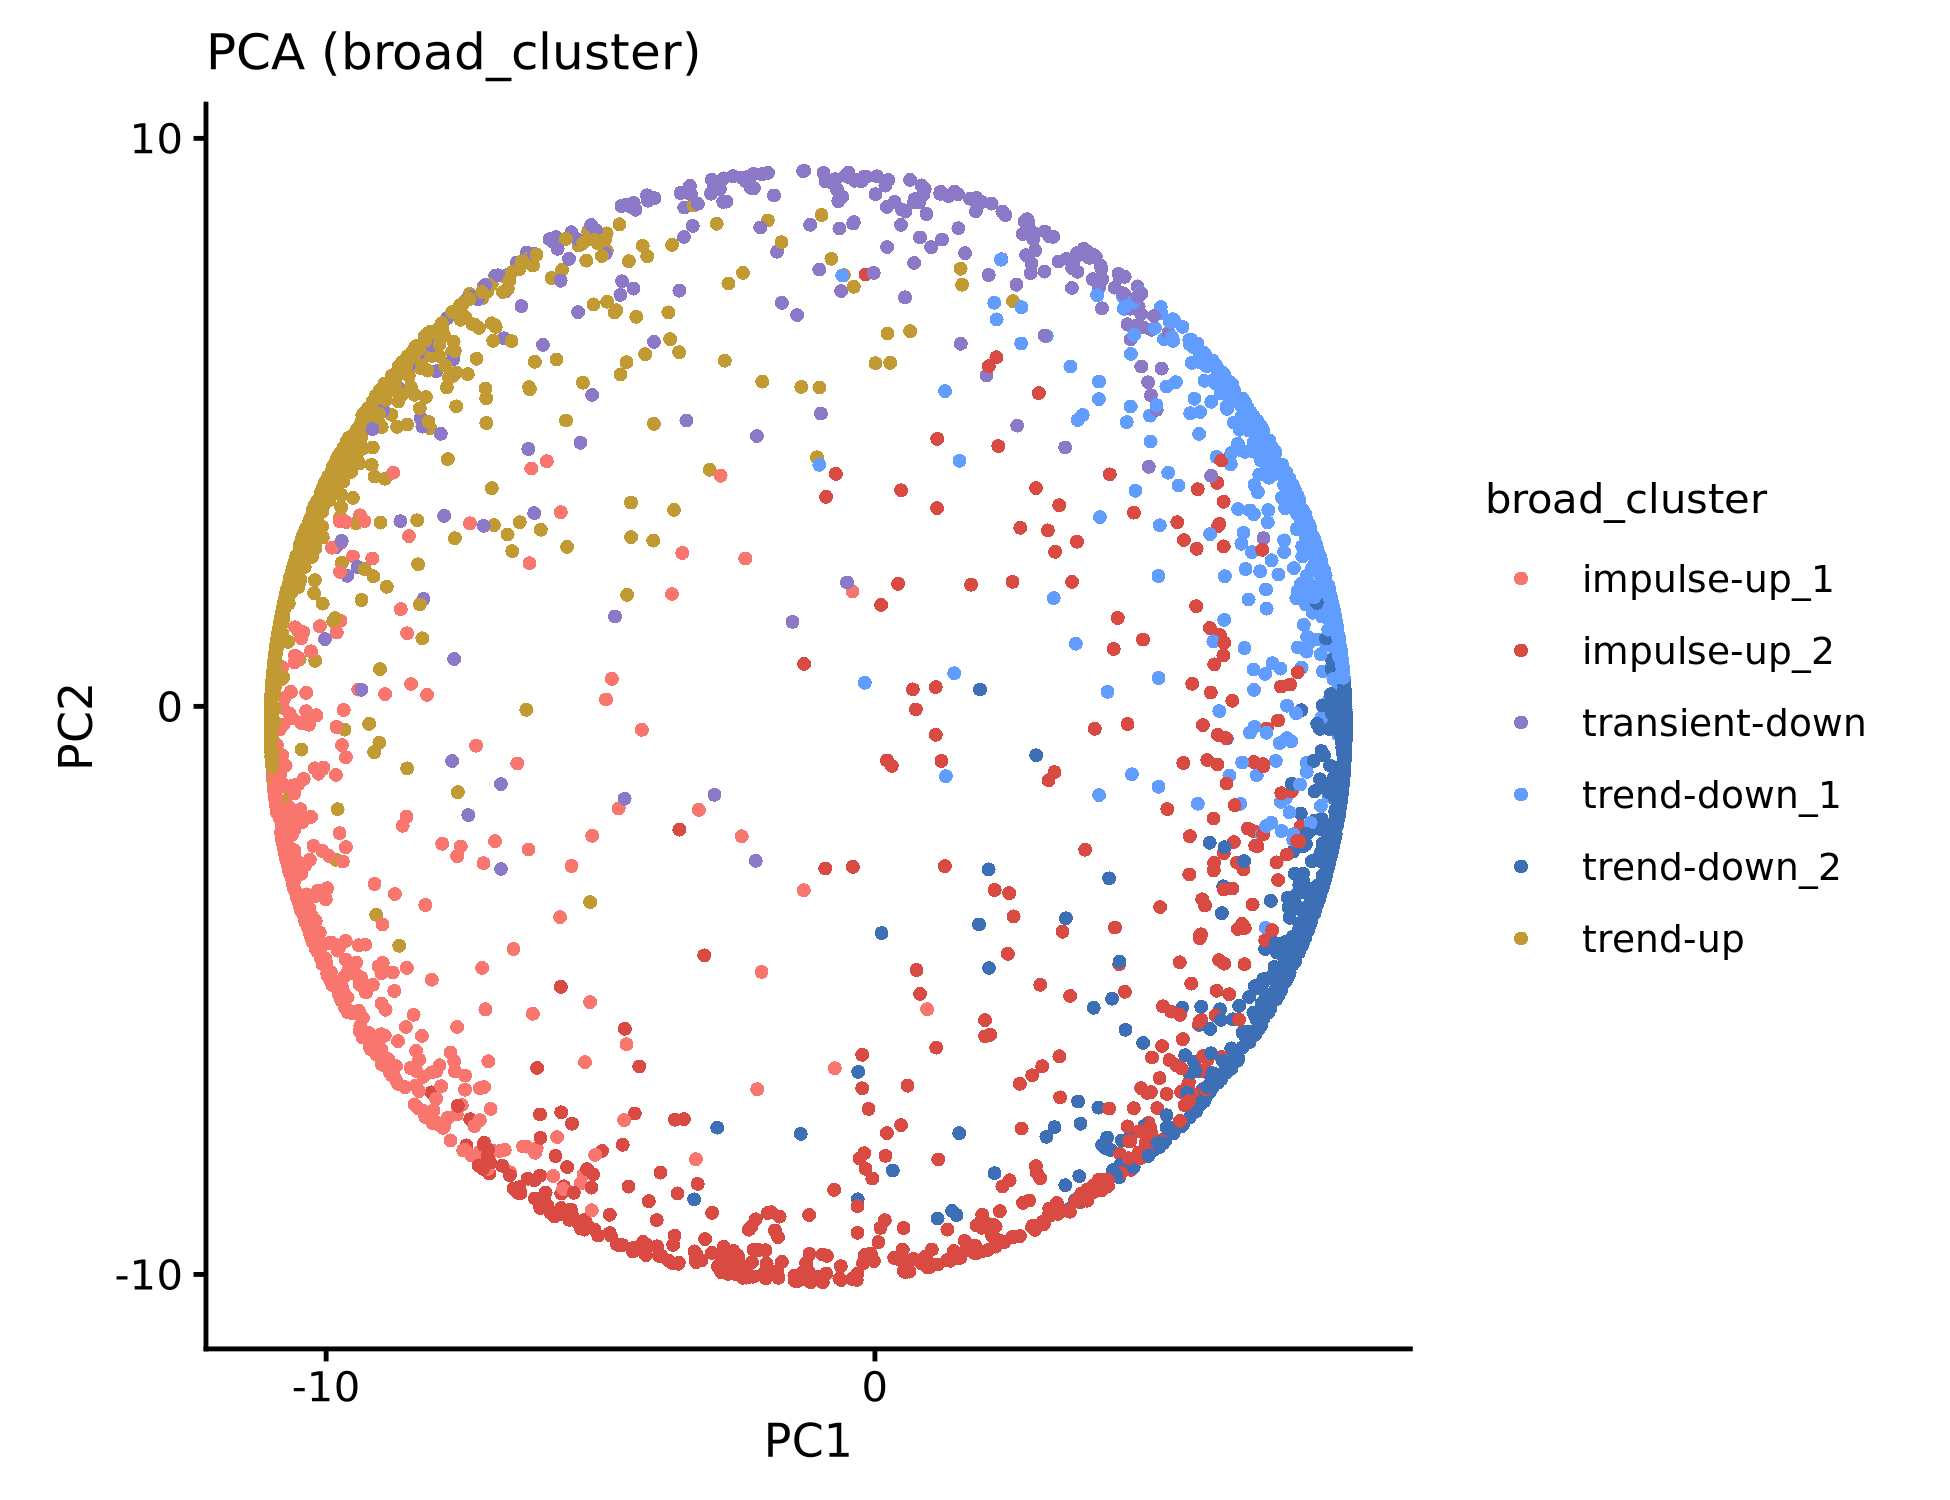

In [16]:
cp.pl.trajectory_features(
    traj,
    basis="X_pca",
    x="PC1",
    y="PC2",
    color="broad_cluster",
    output=PLOT_DIR / "trajectory_feature_space.svg",
)

## Broad dynamic modes

One row per broad mode: median and IQR of the z-scored trajectories (first panel), then the 10 trajectories with the highest Wald statistic. Shown for strongly responding K562 + TNF-alpha trajectories (|peak log2FC| > 0.5).

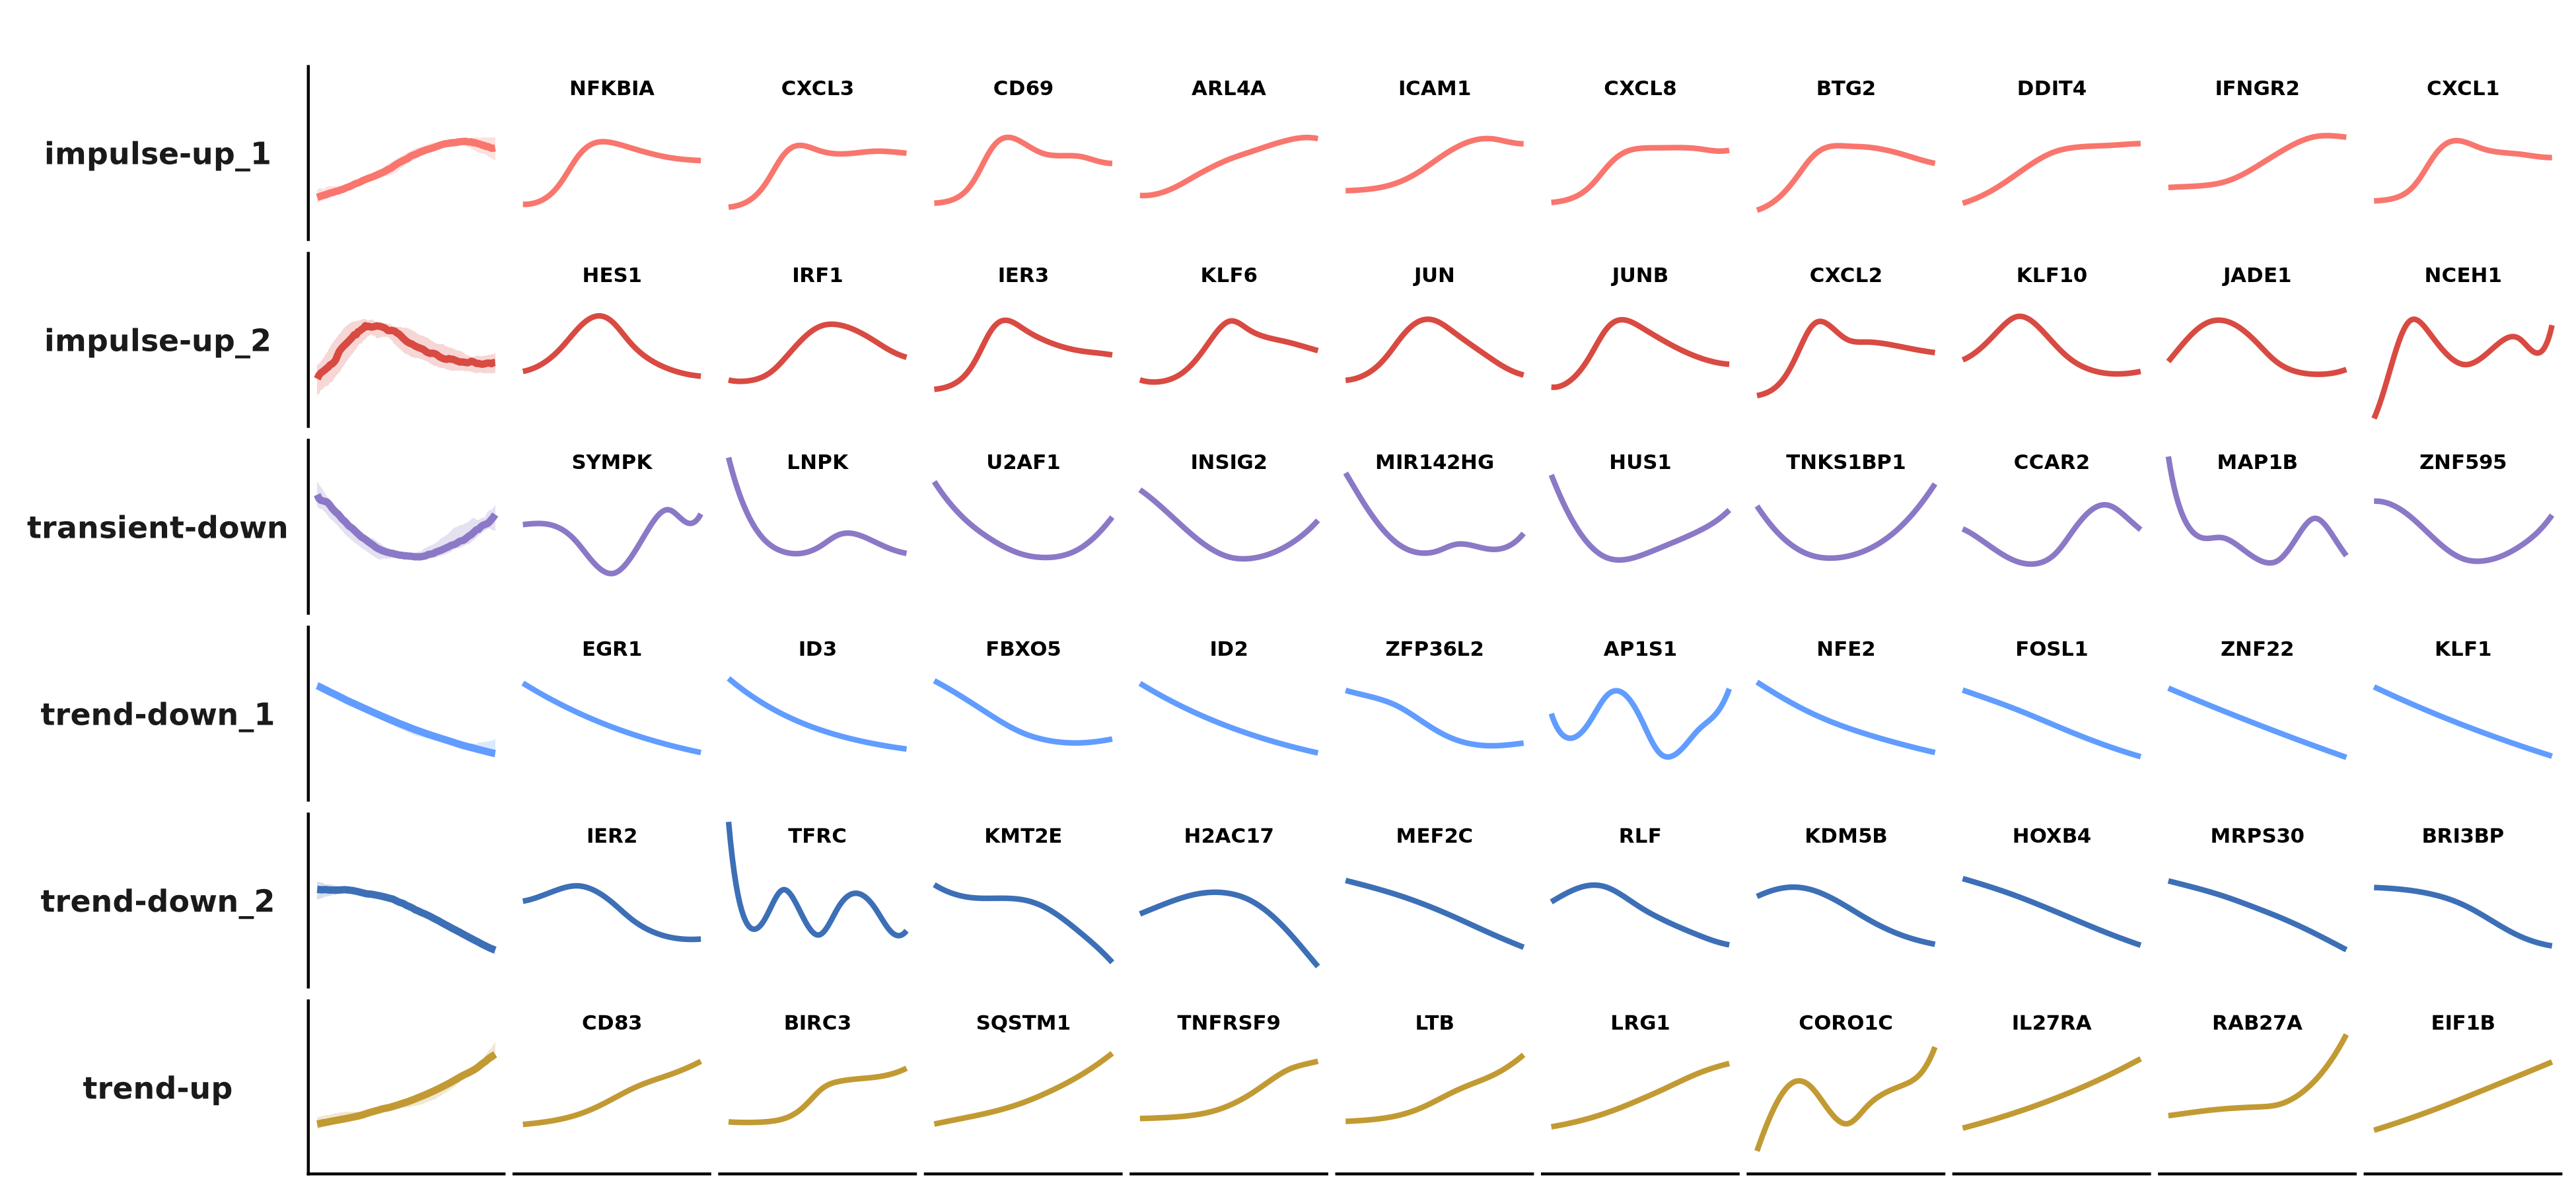

In [17]:
k562a = traj[
    (traj.obs["cell_type"] == "K562a") & (traj.obs["peak_log2fc"].abs() > 0.5) & (traj.obs["pvalue_1"] < 0.05)
]
cp.pl.cluster_medoids_and_top_genes(
    k562a,
    "broad_cluster",
    seed=10,
    top_n=10,
    gene_title_mode="gene_sym",
    use_silhouette_alpha=False,
    show_sil_text=False,
    show_median_iqr=True,
    show_gene_titles=True,
    title="",
    output=PLOT_DIR / "broad_cluster_medoids.svg",
    width=13,
    height=6,
)

## Fine clusters within broad modes

The fine clusters of each broad mode (all contexts), drawn the same way with the 5 top trajectories per fine cluster.

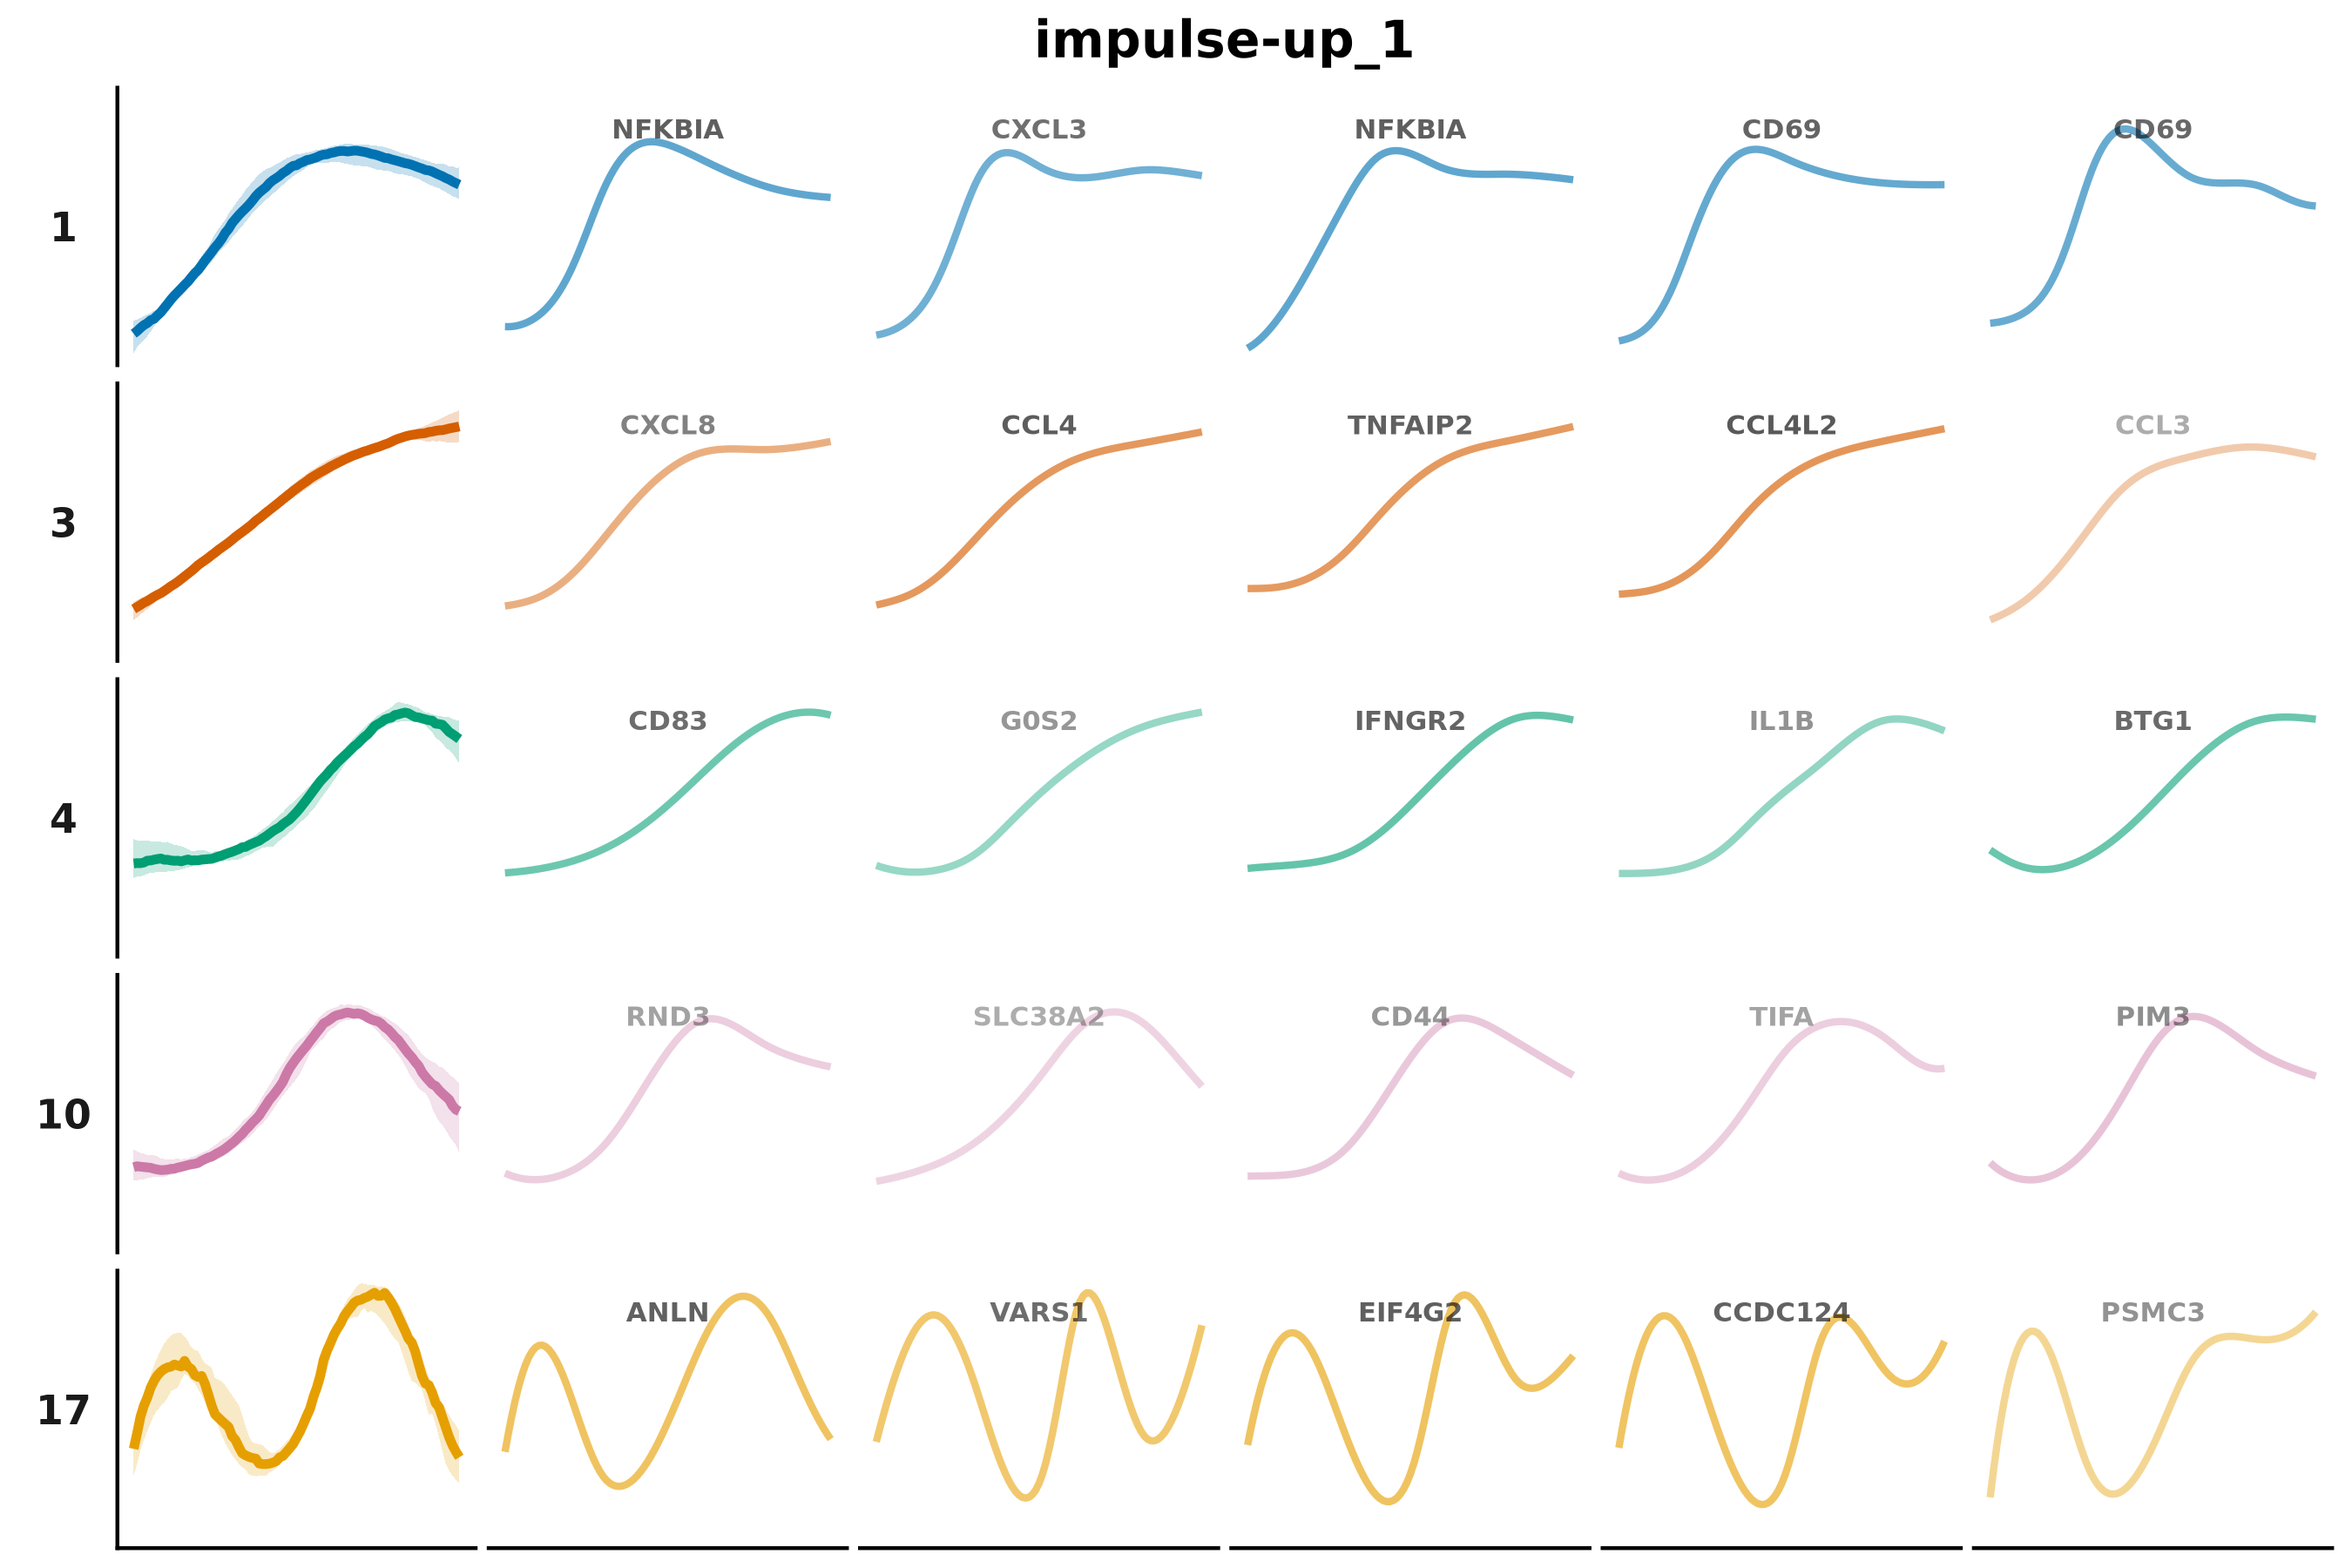

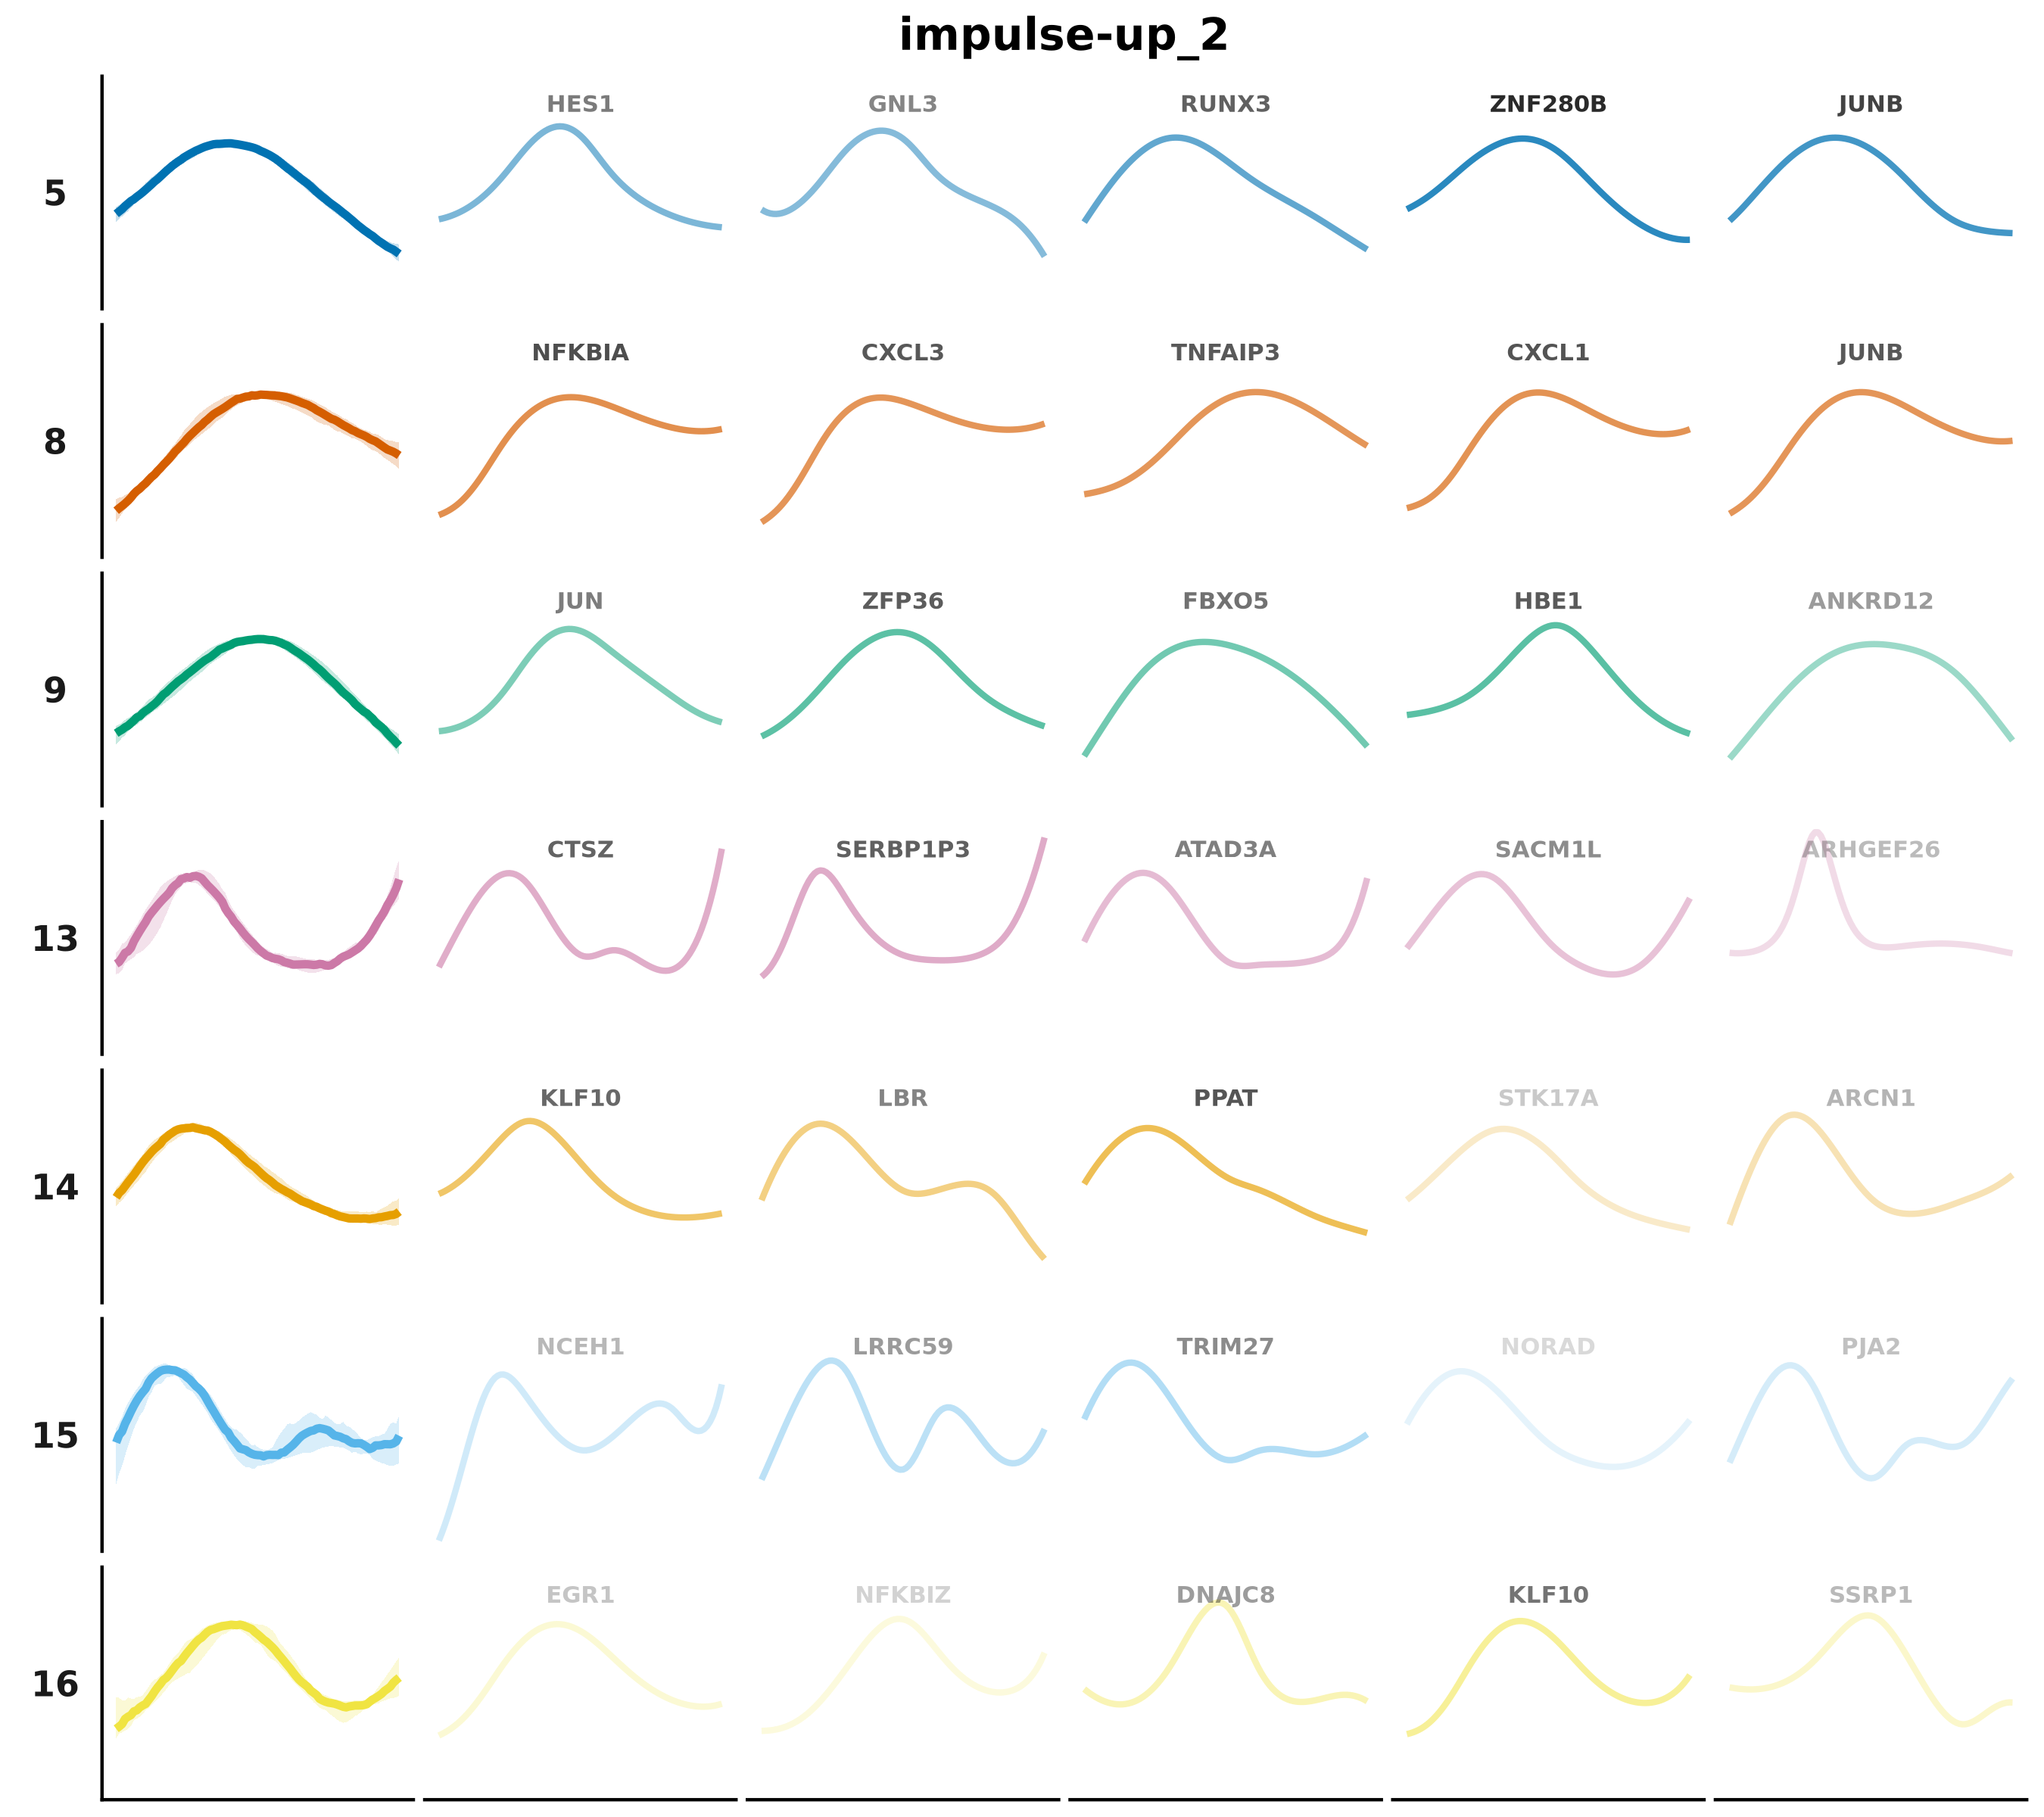

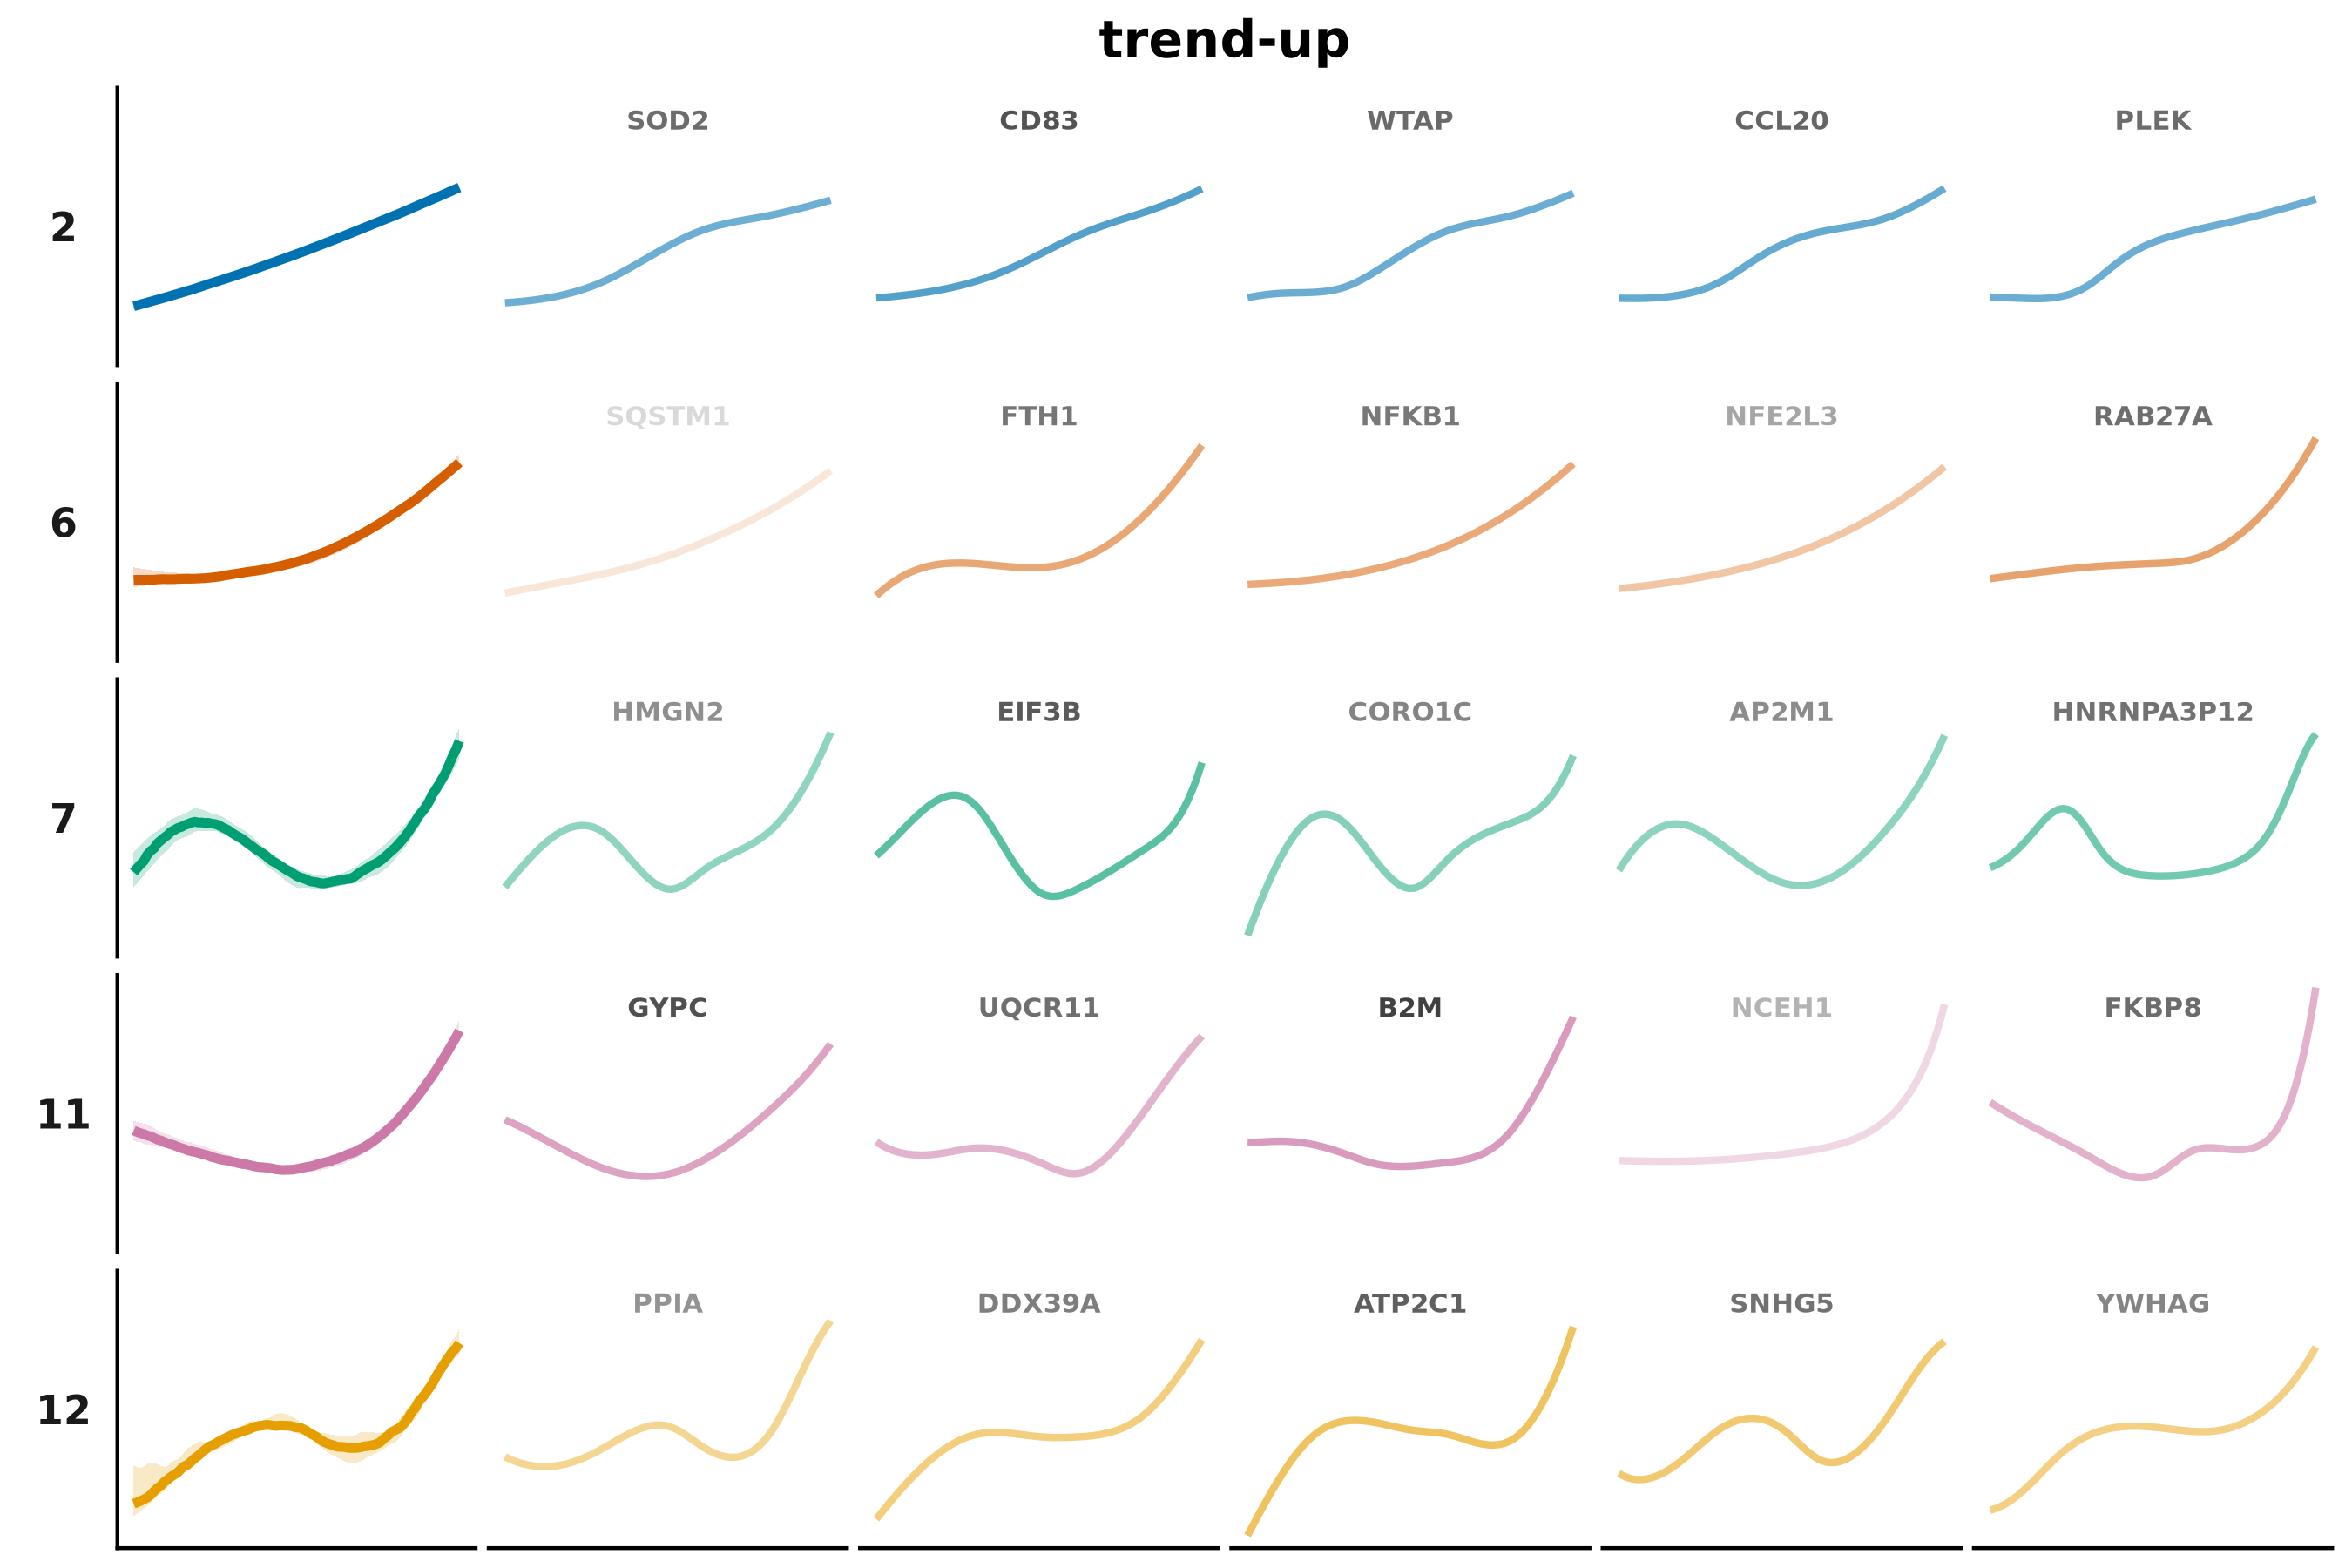

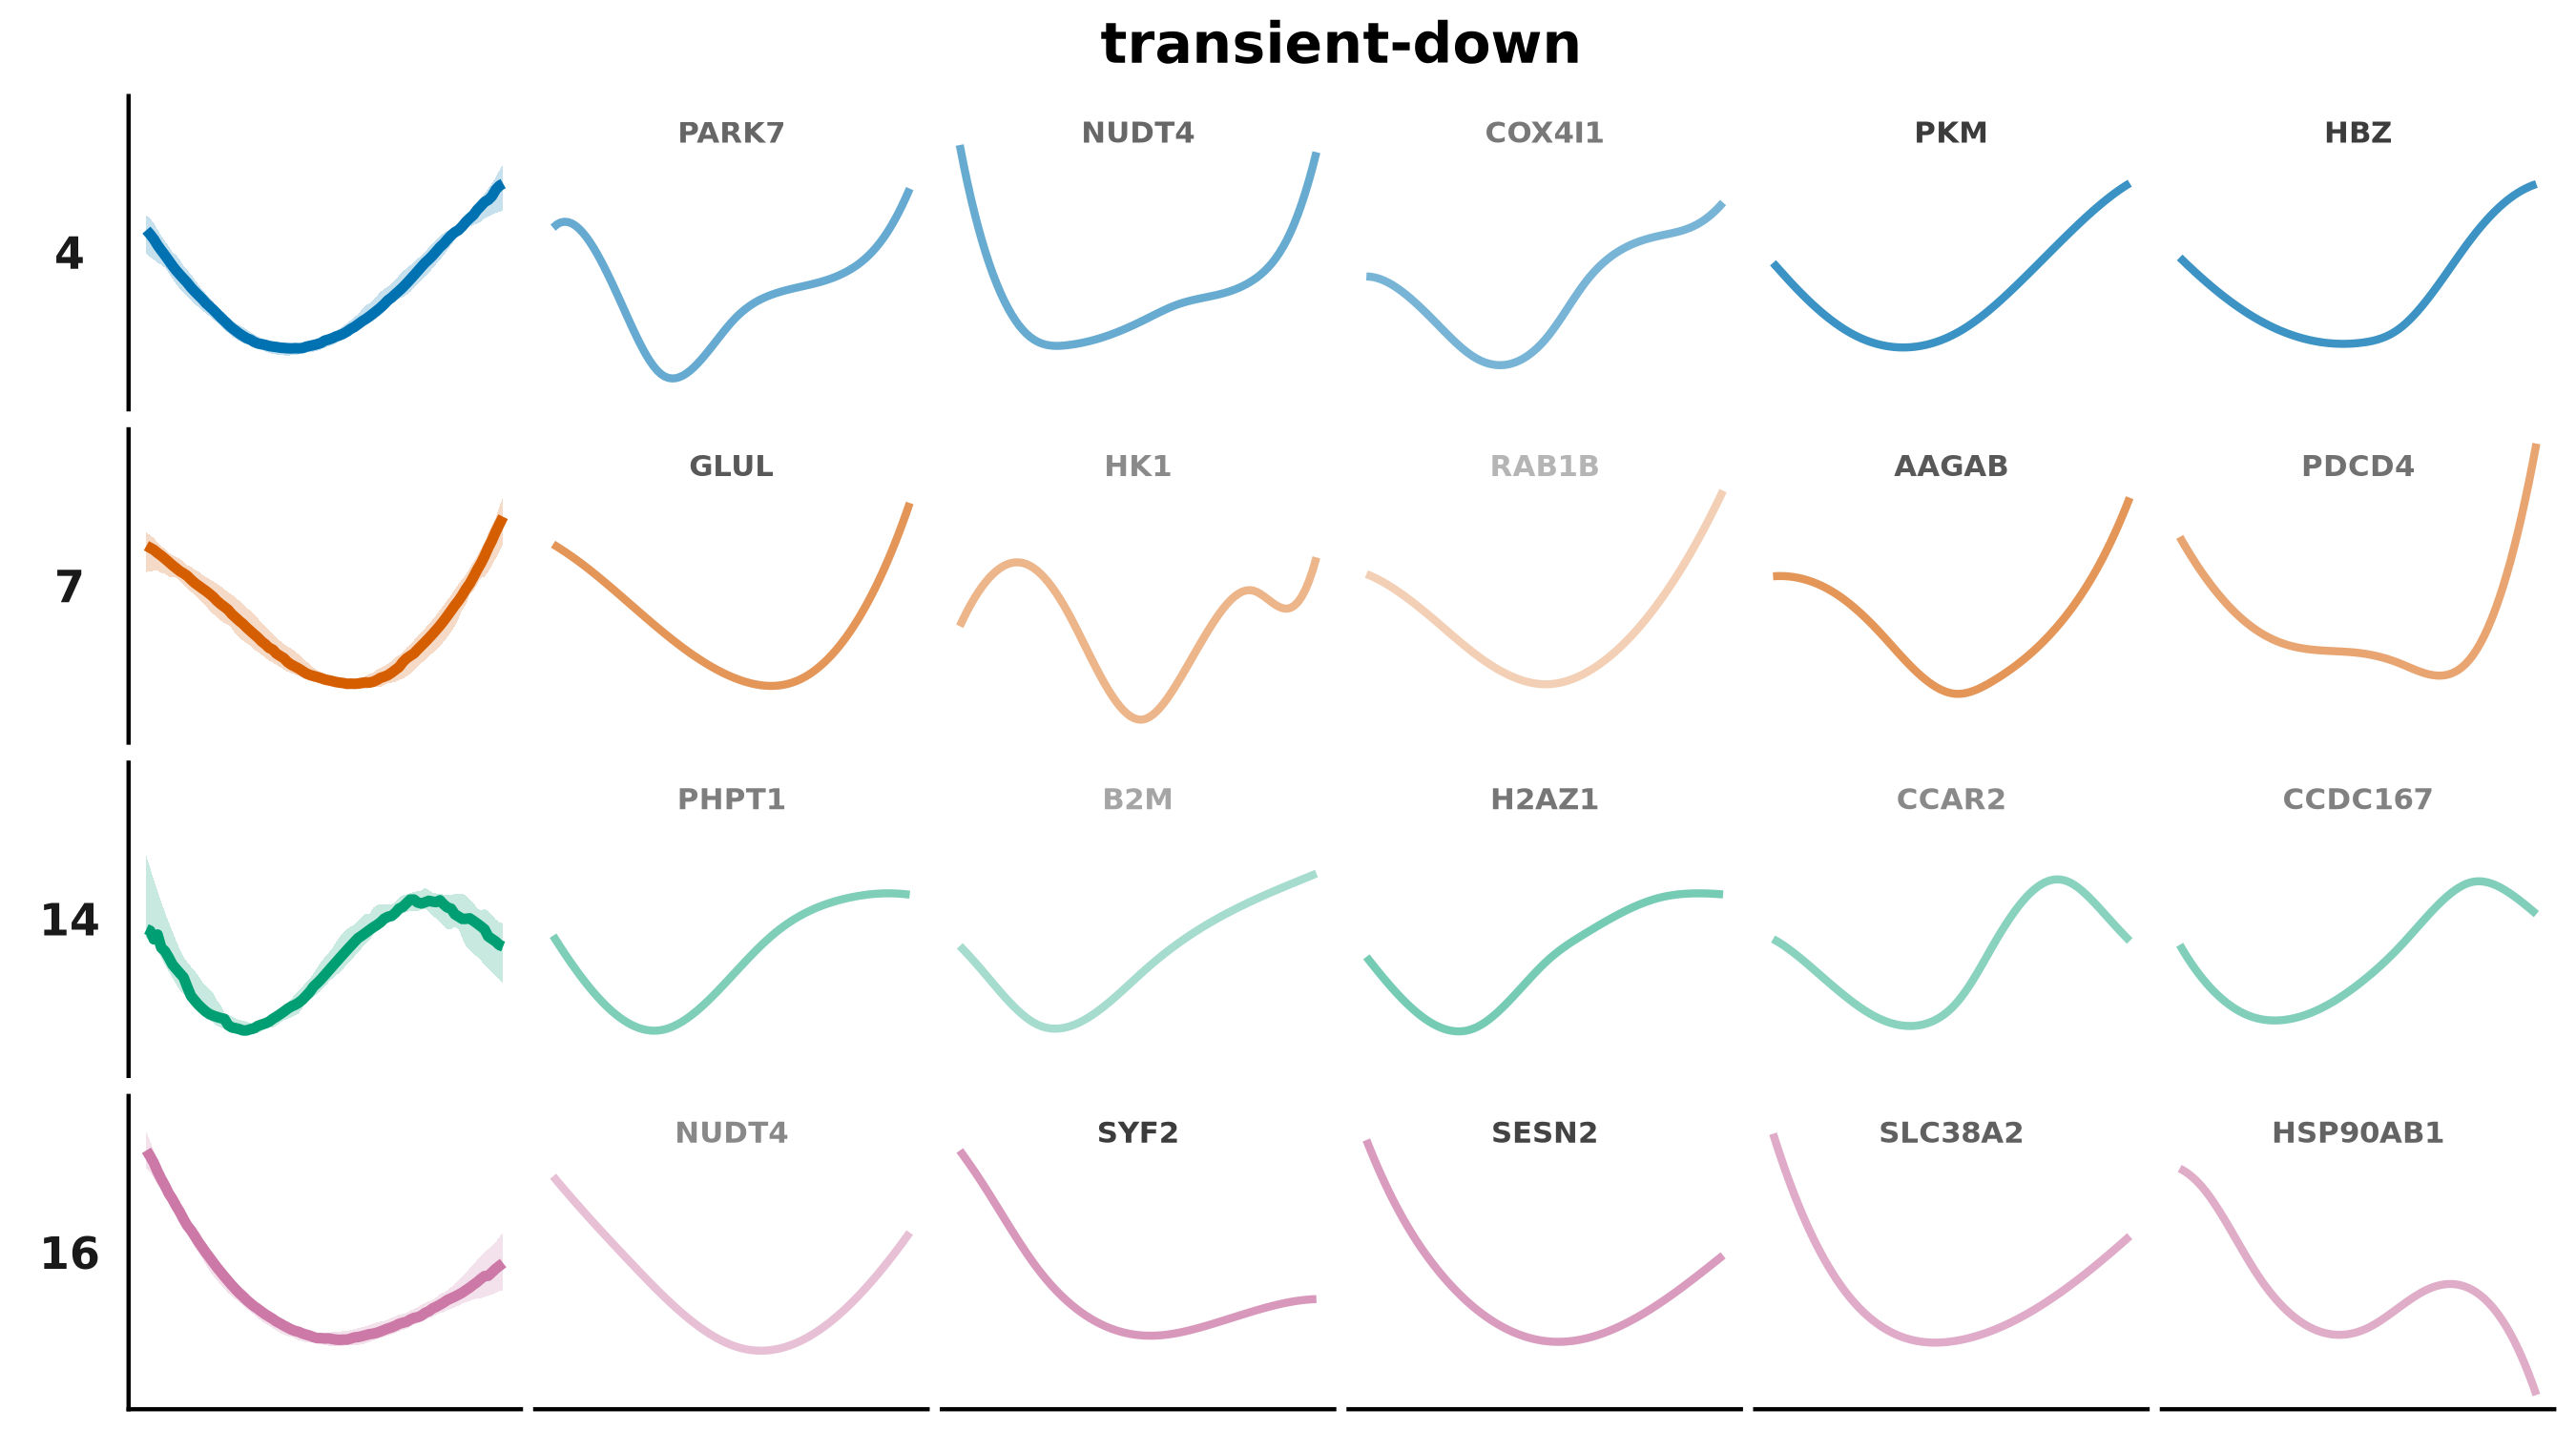

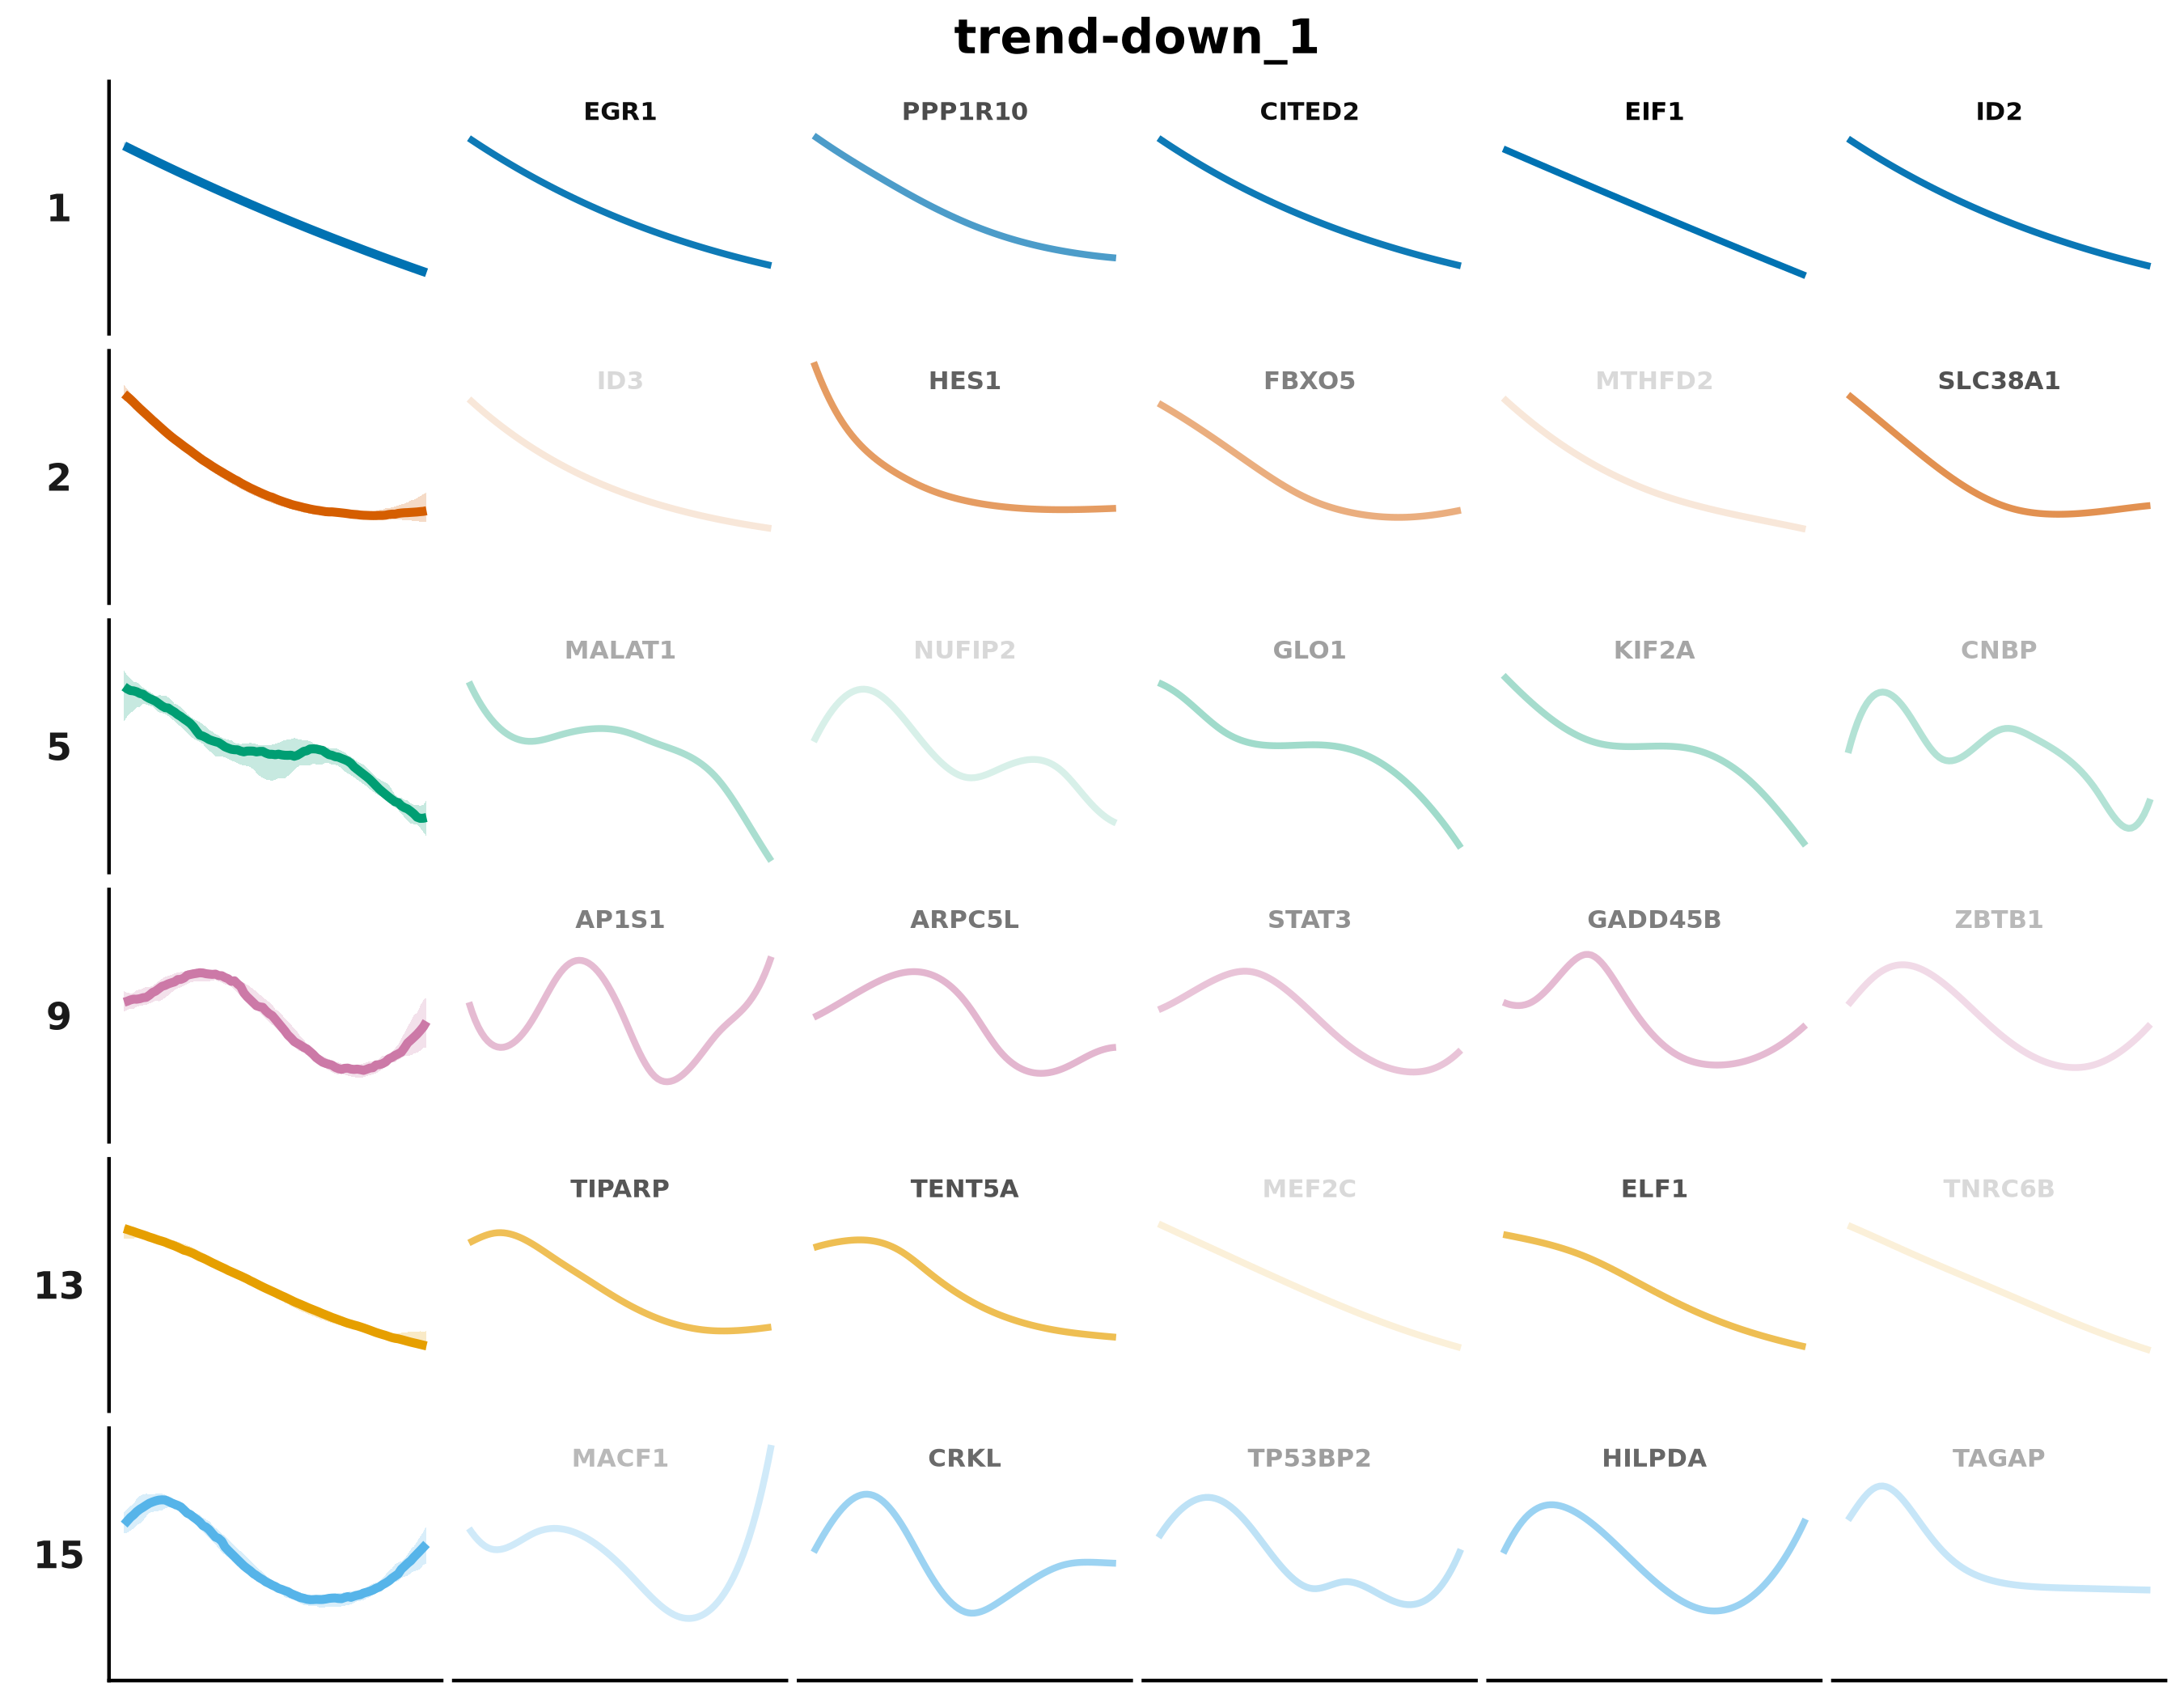

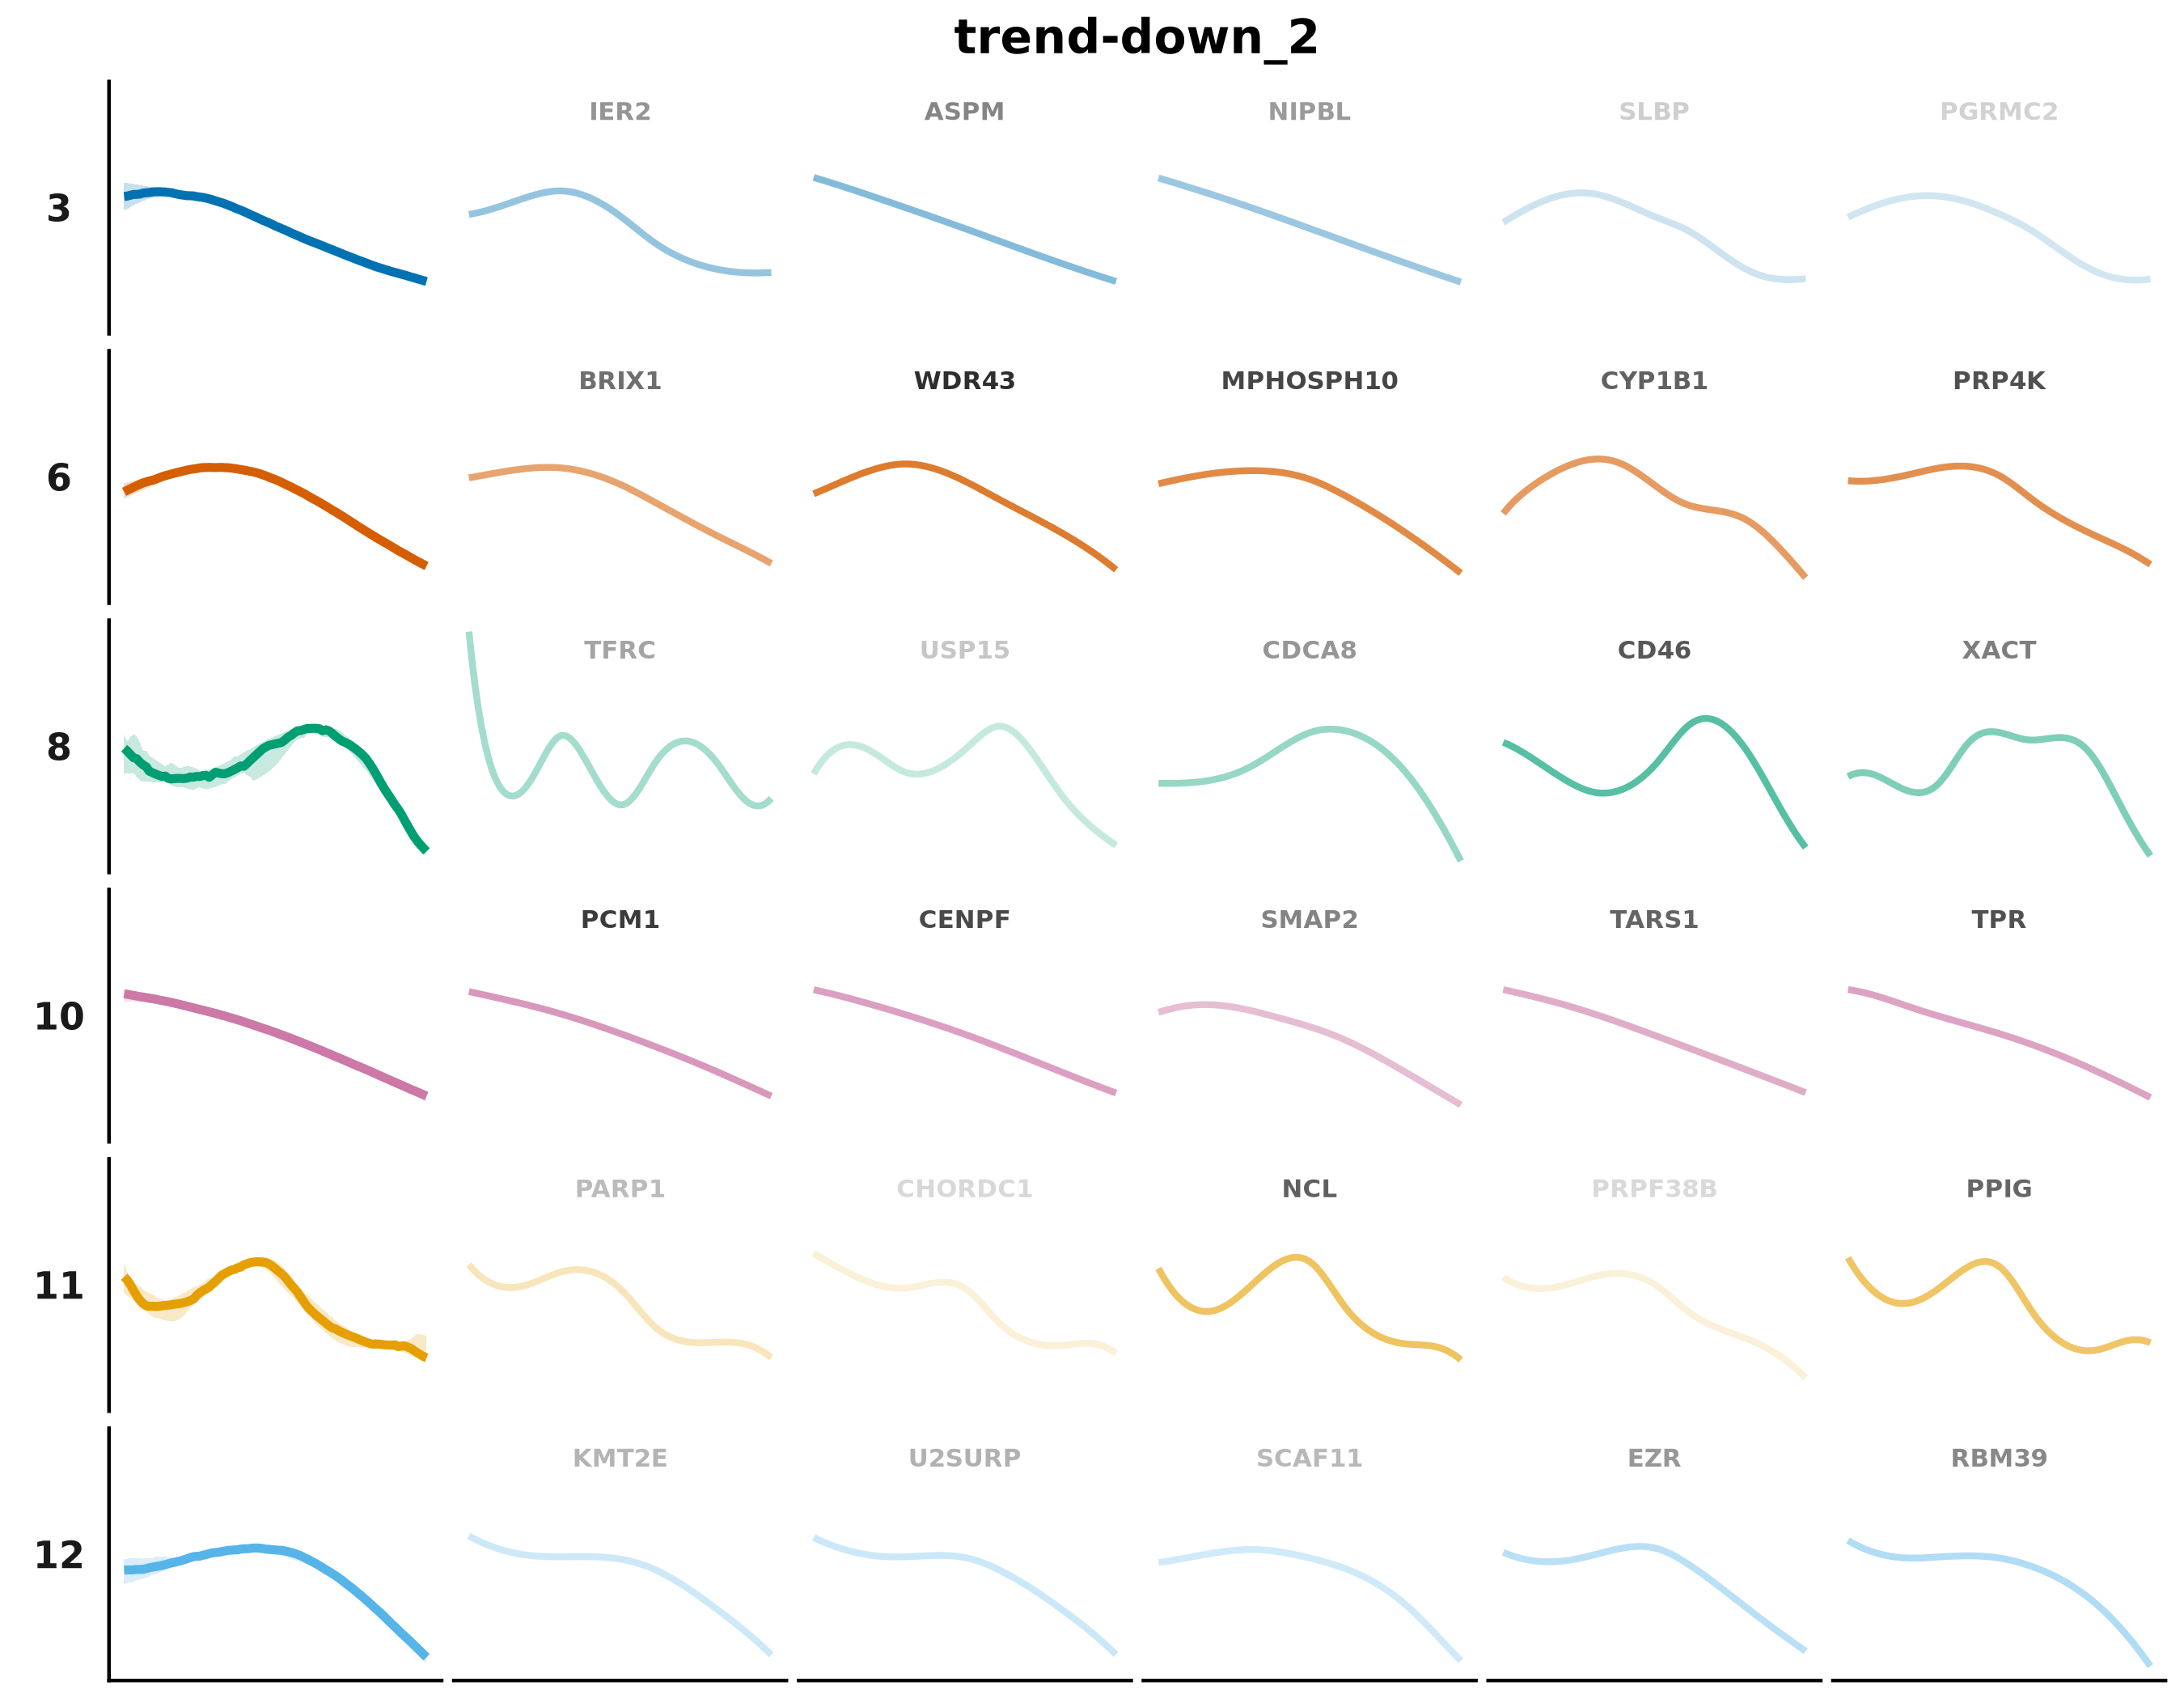

In [18]:
broad_order = ["impulse-up_1", "impulse-up_2", "trend-up", "transient-down", "trend-down_1", "trend-down_2"]

for mode in broad_order:
    fine_col = "cluster_fine_induced" if mode in {"impulse-up_1", "impulse-up_2", "trend-up"} else "cluster_fine_repressed"
    in_mode = traj[traj.obs["broad_cluster"] == mode]
    display(
        cp.pl.cluster_medoids_and_top_genes(
            in_mode,
            fine_col,
            seed=10,
            top_n=5,
            gene_title_mode="gene_sym",
            show_sil_text=False,
            show_median_iqr=True,
            show_gene_titles=True,
            title=mode,
            output=PLOT_DIR / f"fine_cluster_medoids.{mode}.svg",
            width=9,
        )
    )

## Dynamic-mode proportions per context

Proportion of each broad mode among the responsive trajectories of each context: here every significant trajectory (`pvalue_1` < 0.05), without a fold-change cut. The cross-context figures below use the same trajectories.

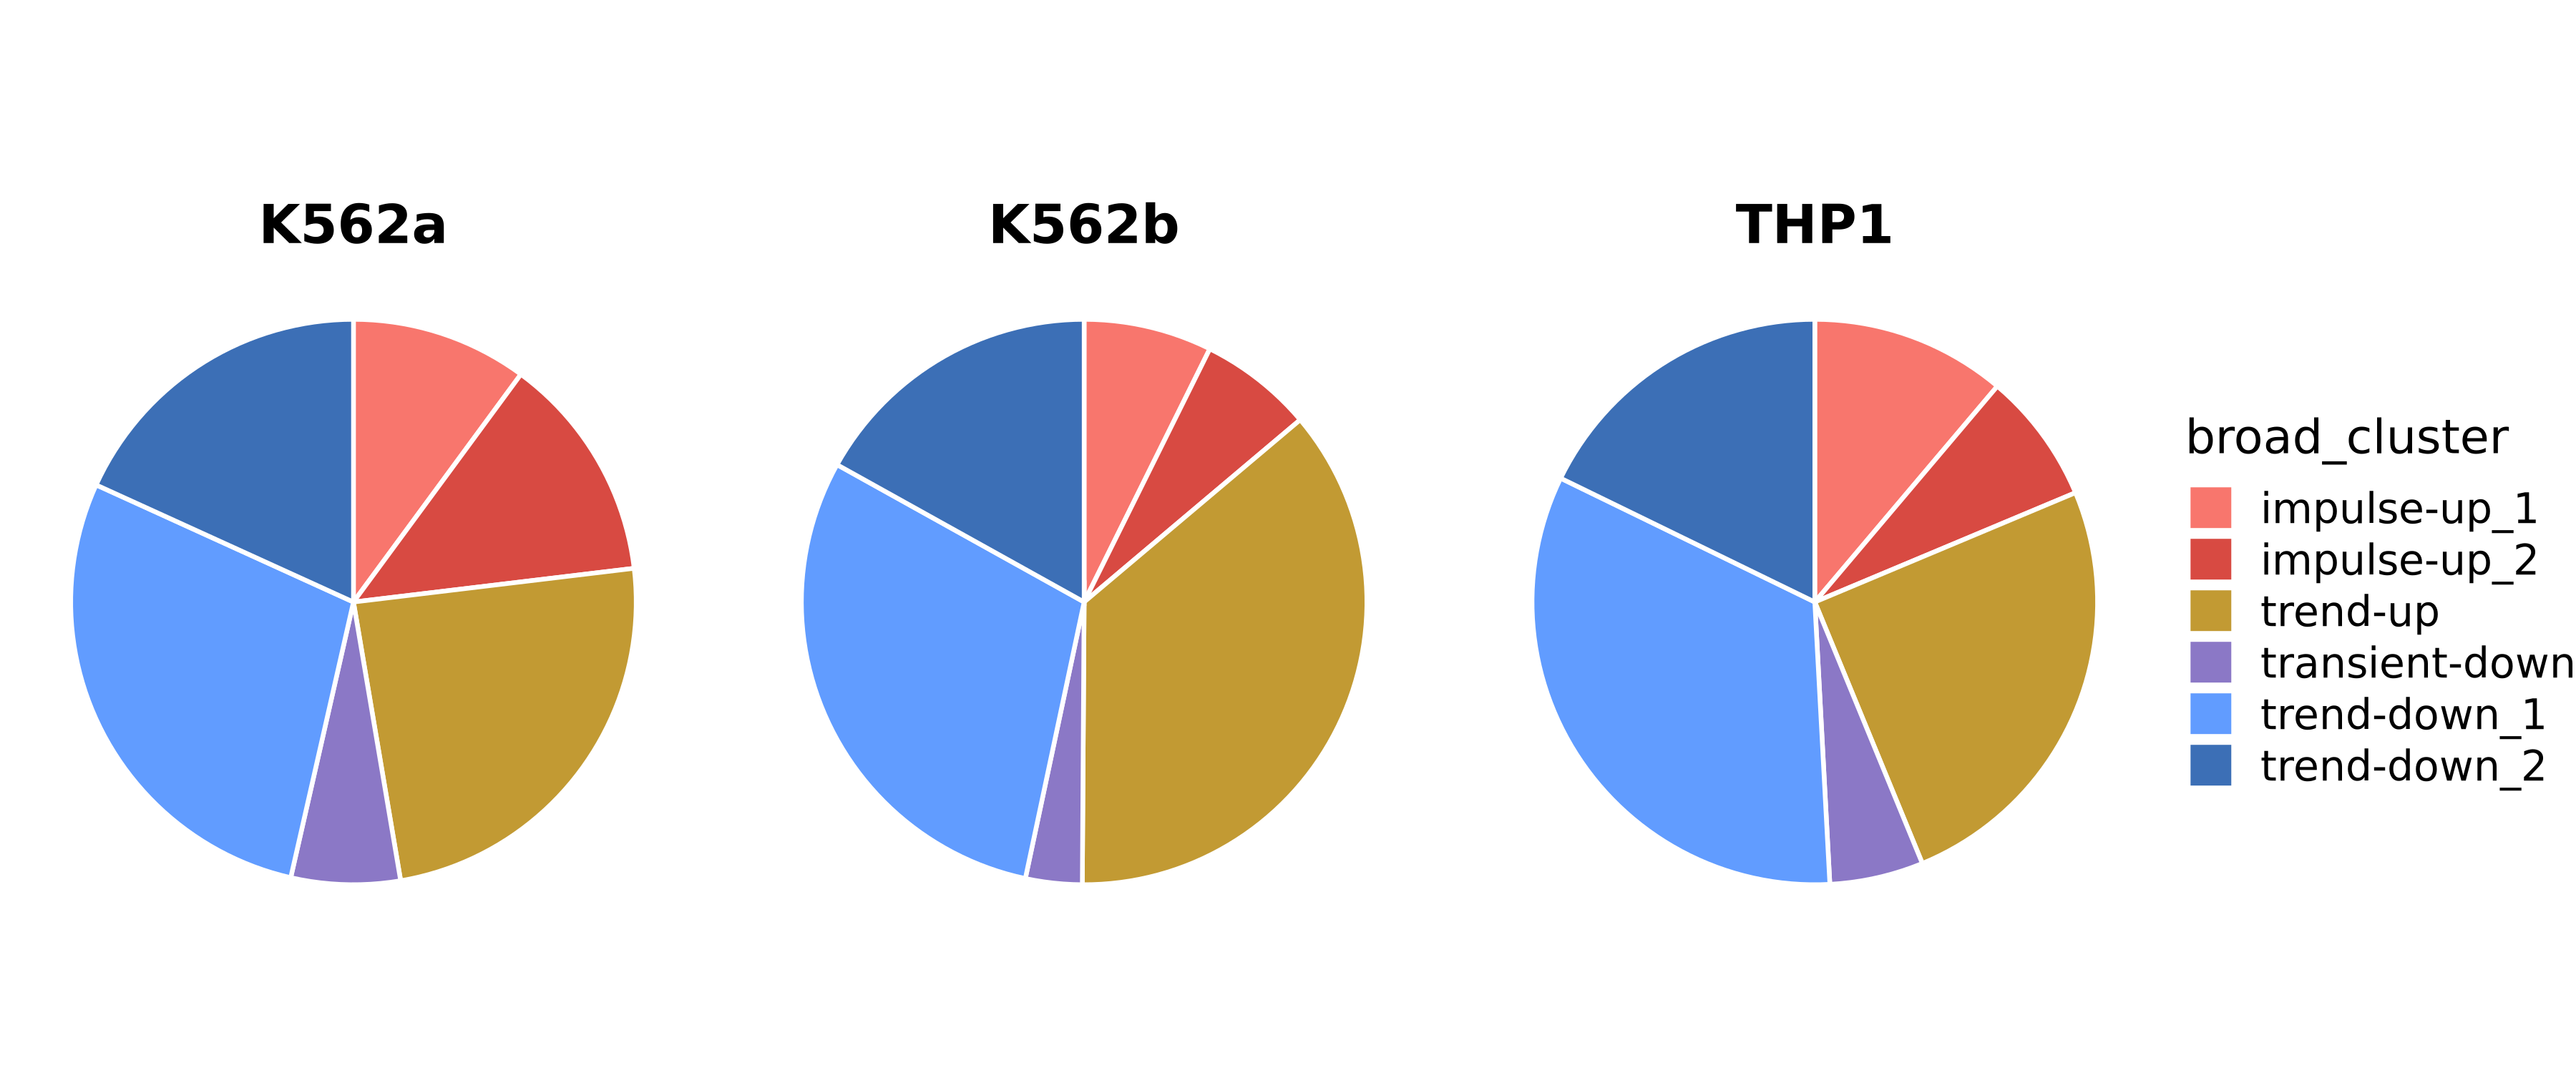

cell_type,K562a,K562b,THP1
broad_cluster,,,
impulse-up_1,0.101,0.073,0.112
impulse-up_2,0.130,0.065,0.075
transient-down,0.062,0.032,0.054
trend-down_1,0.282,0.297,0.331
trend-down_2,0.182,0.169,0.178
trend-up,0.242,0.363,0.251


In [19]:
responsive = traj[traj.obs["pvalue_1"] < 0.05].copy()

proportions = cp.pl.mode_proportions(responsive, output=PLOT_DIR / "mode_proportions.svg")
display(proportions)
proportions.data.pivot(index="broad_cluster", columns="cell_type", values="prop").round(3)

Paired modes grouped (impulse-up = impulse-up_1 + impulse-up_2, trend-down = trend-down_1 + trend-down_2): percent of responsive genes per context and, in the last row, the range across contexts in whole percents (the manuscript quotes the ranges of `01_GeneTrajectoryClustering.ipynb`, which also requires |peak log2FC| >= 0.5).

In [20]:
mode_groups = {
    "impulse-up_1": "impulse-up",
    "impulse-up_2": "impulse-up",
    "trend-up": "trend-up",
    "trend-down_1": "trend-down",
    "trend-down_2": "trend-down",
    "transient-down": "transient-down",
}
pct = (
    proportions.data.assign(mode=proportions.data["broad_cluster"].map(mode_groups))
    .pivot_table(index="cell_type", columns="mode", values="prop", aggfunc="sum")
    .loc[:, ["impulse-up", "trend-up", "trend-down", "transient-down"]]
    * 100
)
ranges = pct.round().astype(int).agg(lambda col: f"{col.min()}-{col.max()}")
pd.concat([pct.round(1), ranges.to_frame("range (%)").T])

mode,impulse-up,trend-up,trend-down,transient-down
K562a,23.1,24.2,46.4,6.2
K562b,13.8,36.3,46.7,3.2
THP1,18.7,25.1,50.8,5.4
range (%),14-23,24-36,46-51,3-6


## Mode reassignment between contexts

For each pair of contexts, the top 100 genes by Wald statistic in either context and their broad mode in both (flows of at least 2 genes). Genes without a significant mode in the other context are `low_significance`.

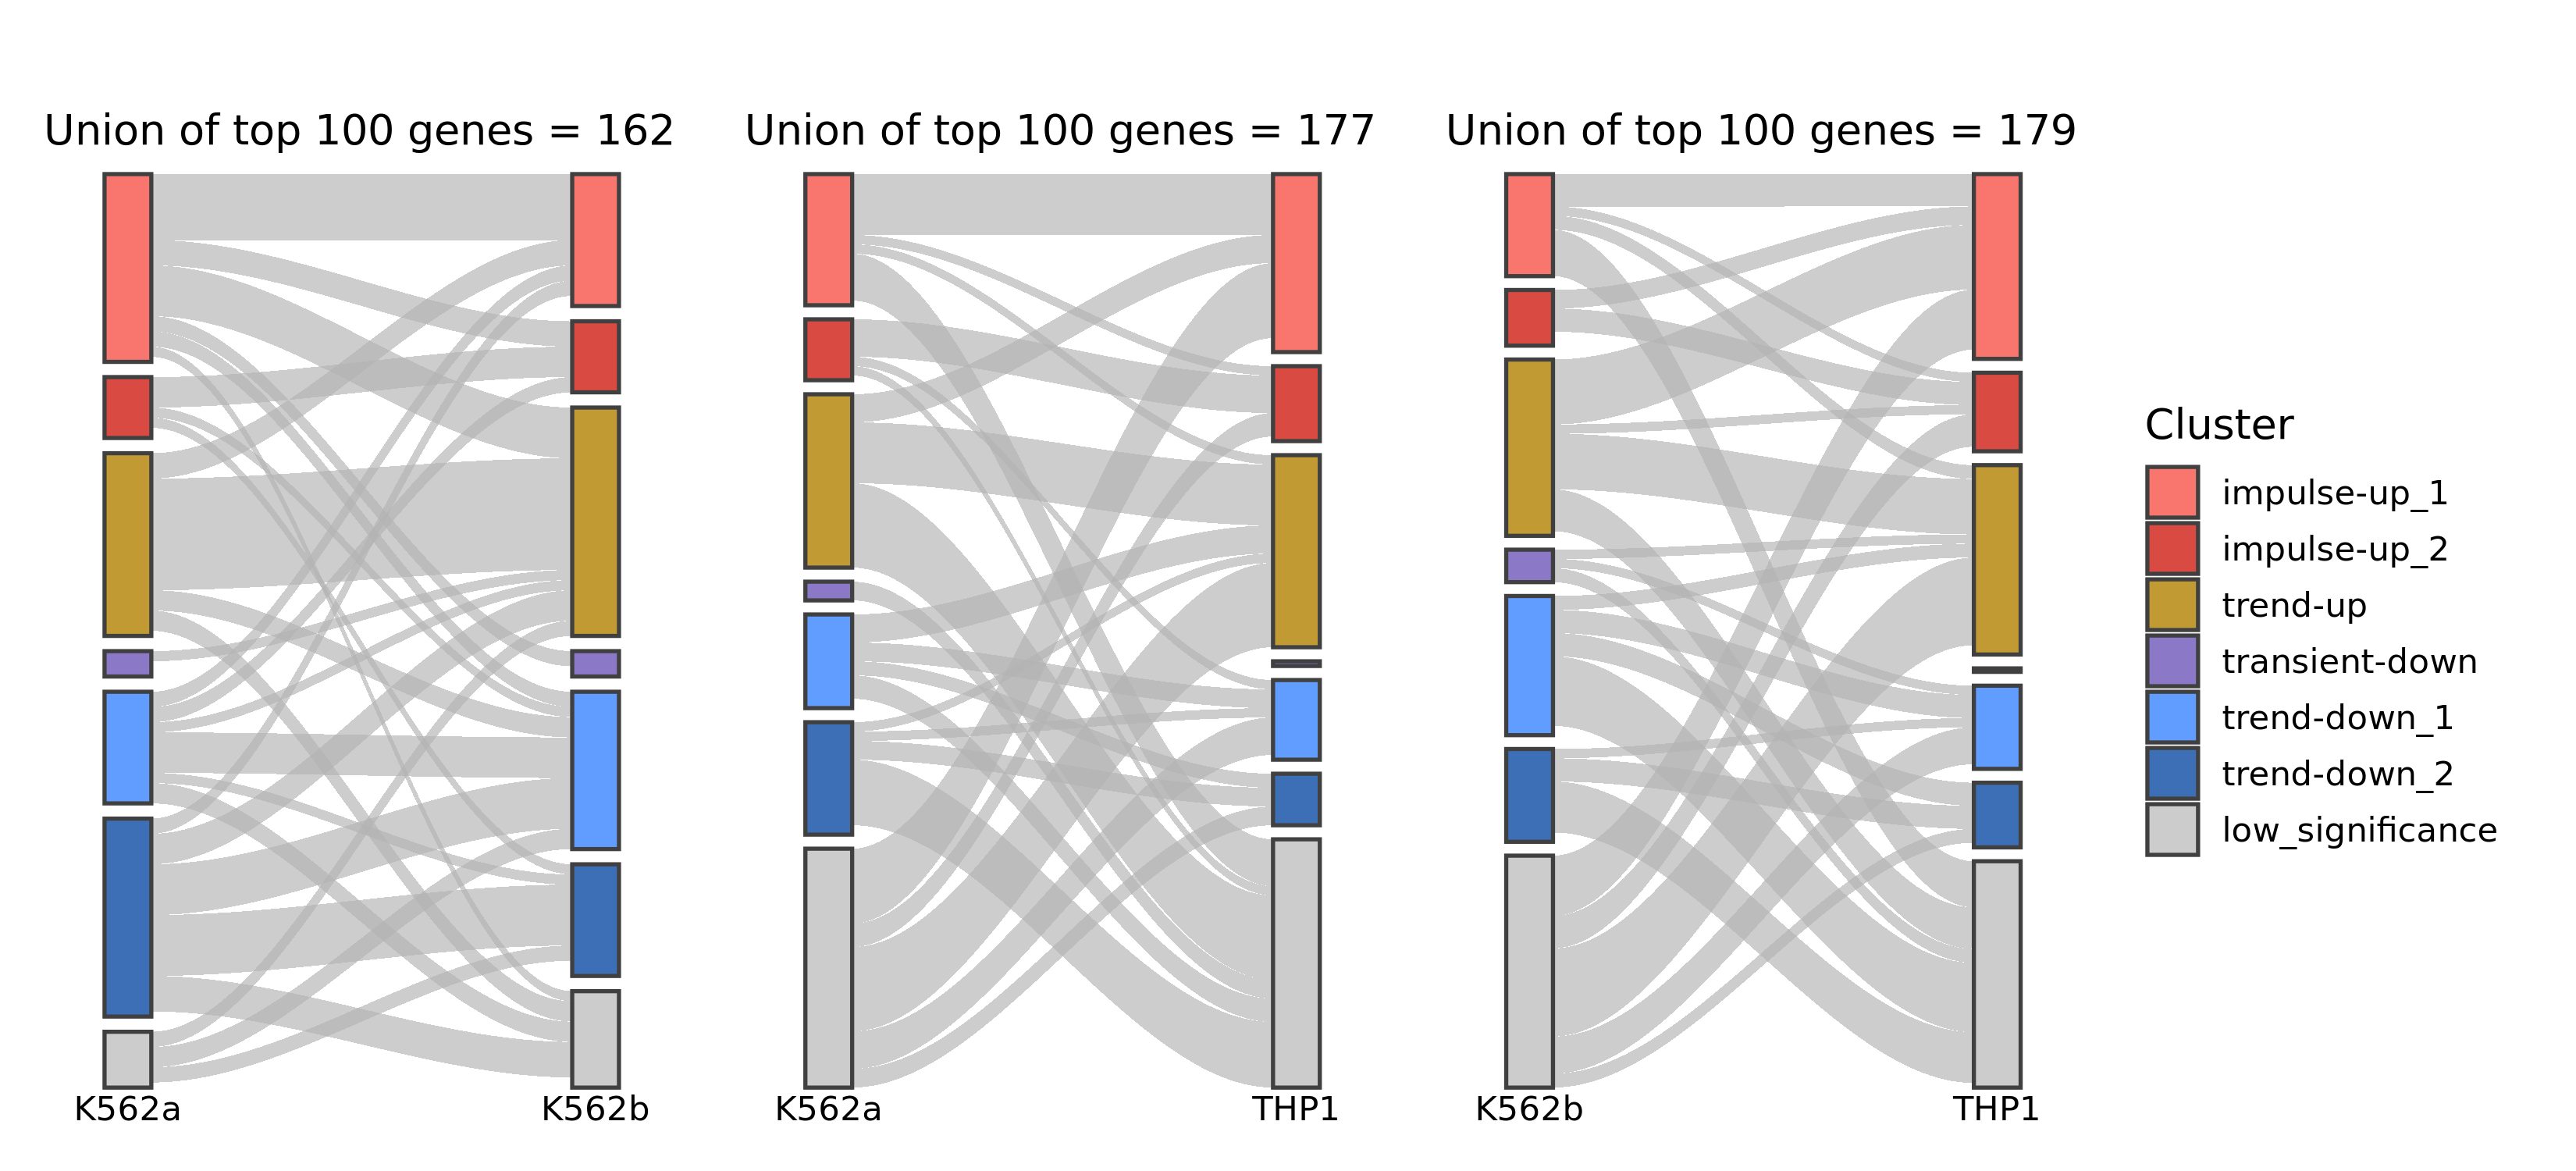

In [21]:
cp.pl.mode_sankey(
    responsive,
    pairs=[("K562a", "K562b"), ("K562a", "THP1"), ("K562b", "THP1")],
    top_k=100,
    output=PLOT_DIR / "mode_reassignment_sankeys.svg",
)

## Top-k mode recovery

Fraction of the 100 top source genes (by Wald statistic, q < 0.05) of a response direction (induced: impulse-up / trend-up modes; repressed: trend-down / transient-down) that have the same direction, with q < 0.05, in the target context.

In [22]:
cp.tl.topk_mode_recovery(
    responsive,
    pairs=[("K562a", "K562b"), ("K562a", "THP1"), ("THP1", "K562b")],
    modes=["induced", "repressed"],
    k=100,
)

,mode,source,target,k,recovery
0,induced,K562a,K562b,100,0.71
1,induced,K562a,THP1,100,0.35
2,induced,THP1,K562b,100,0.32
3,repressed,K562a,K562b,100,0.36
4,repressed,K562a,THP1,100,0.12
5,repressed,THP1,K562b,100,0.23


## Pairwise chord diagram

Mode reassignment among all three contexts: the union of each context's top 100 genes, links of at least 3 genes between modes of different contexts. Low-significance assignments are summarised as grey bars.

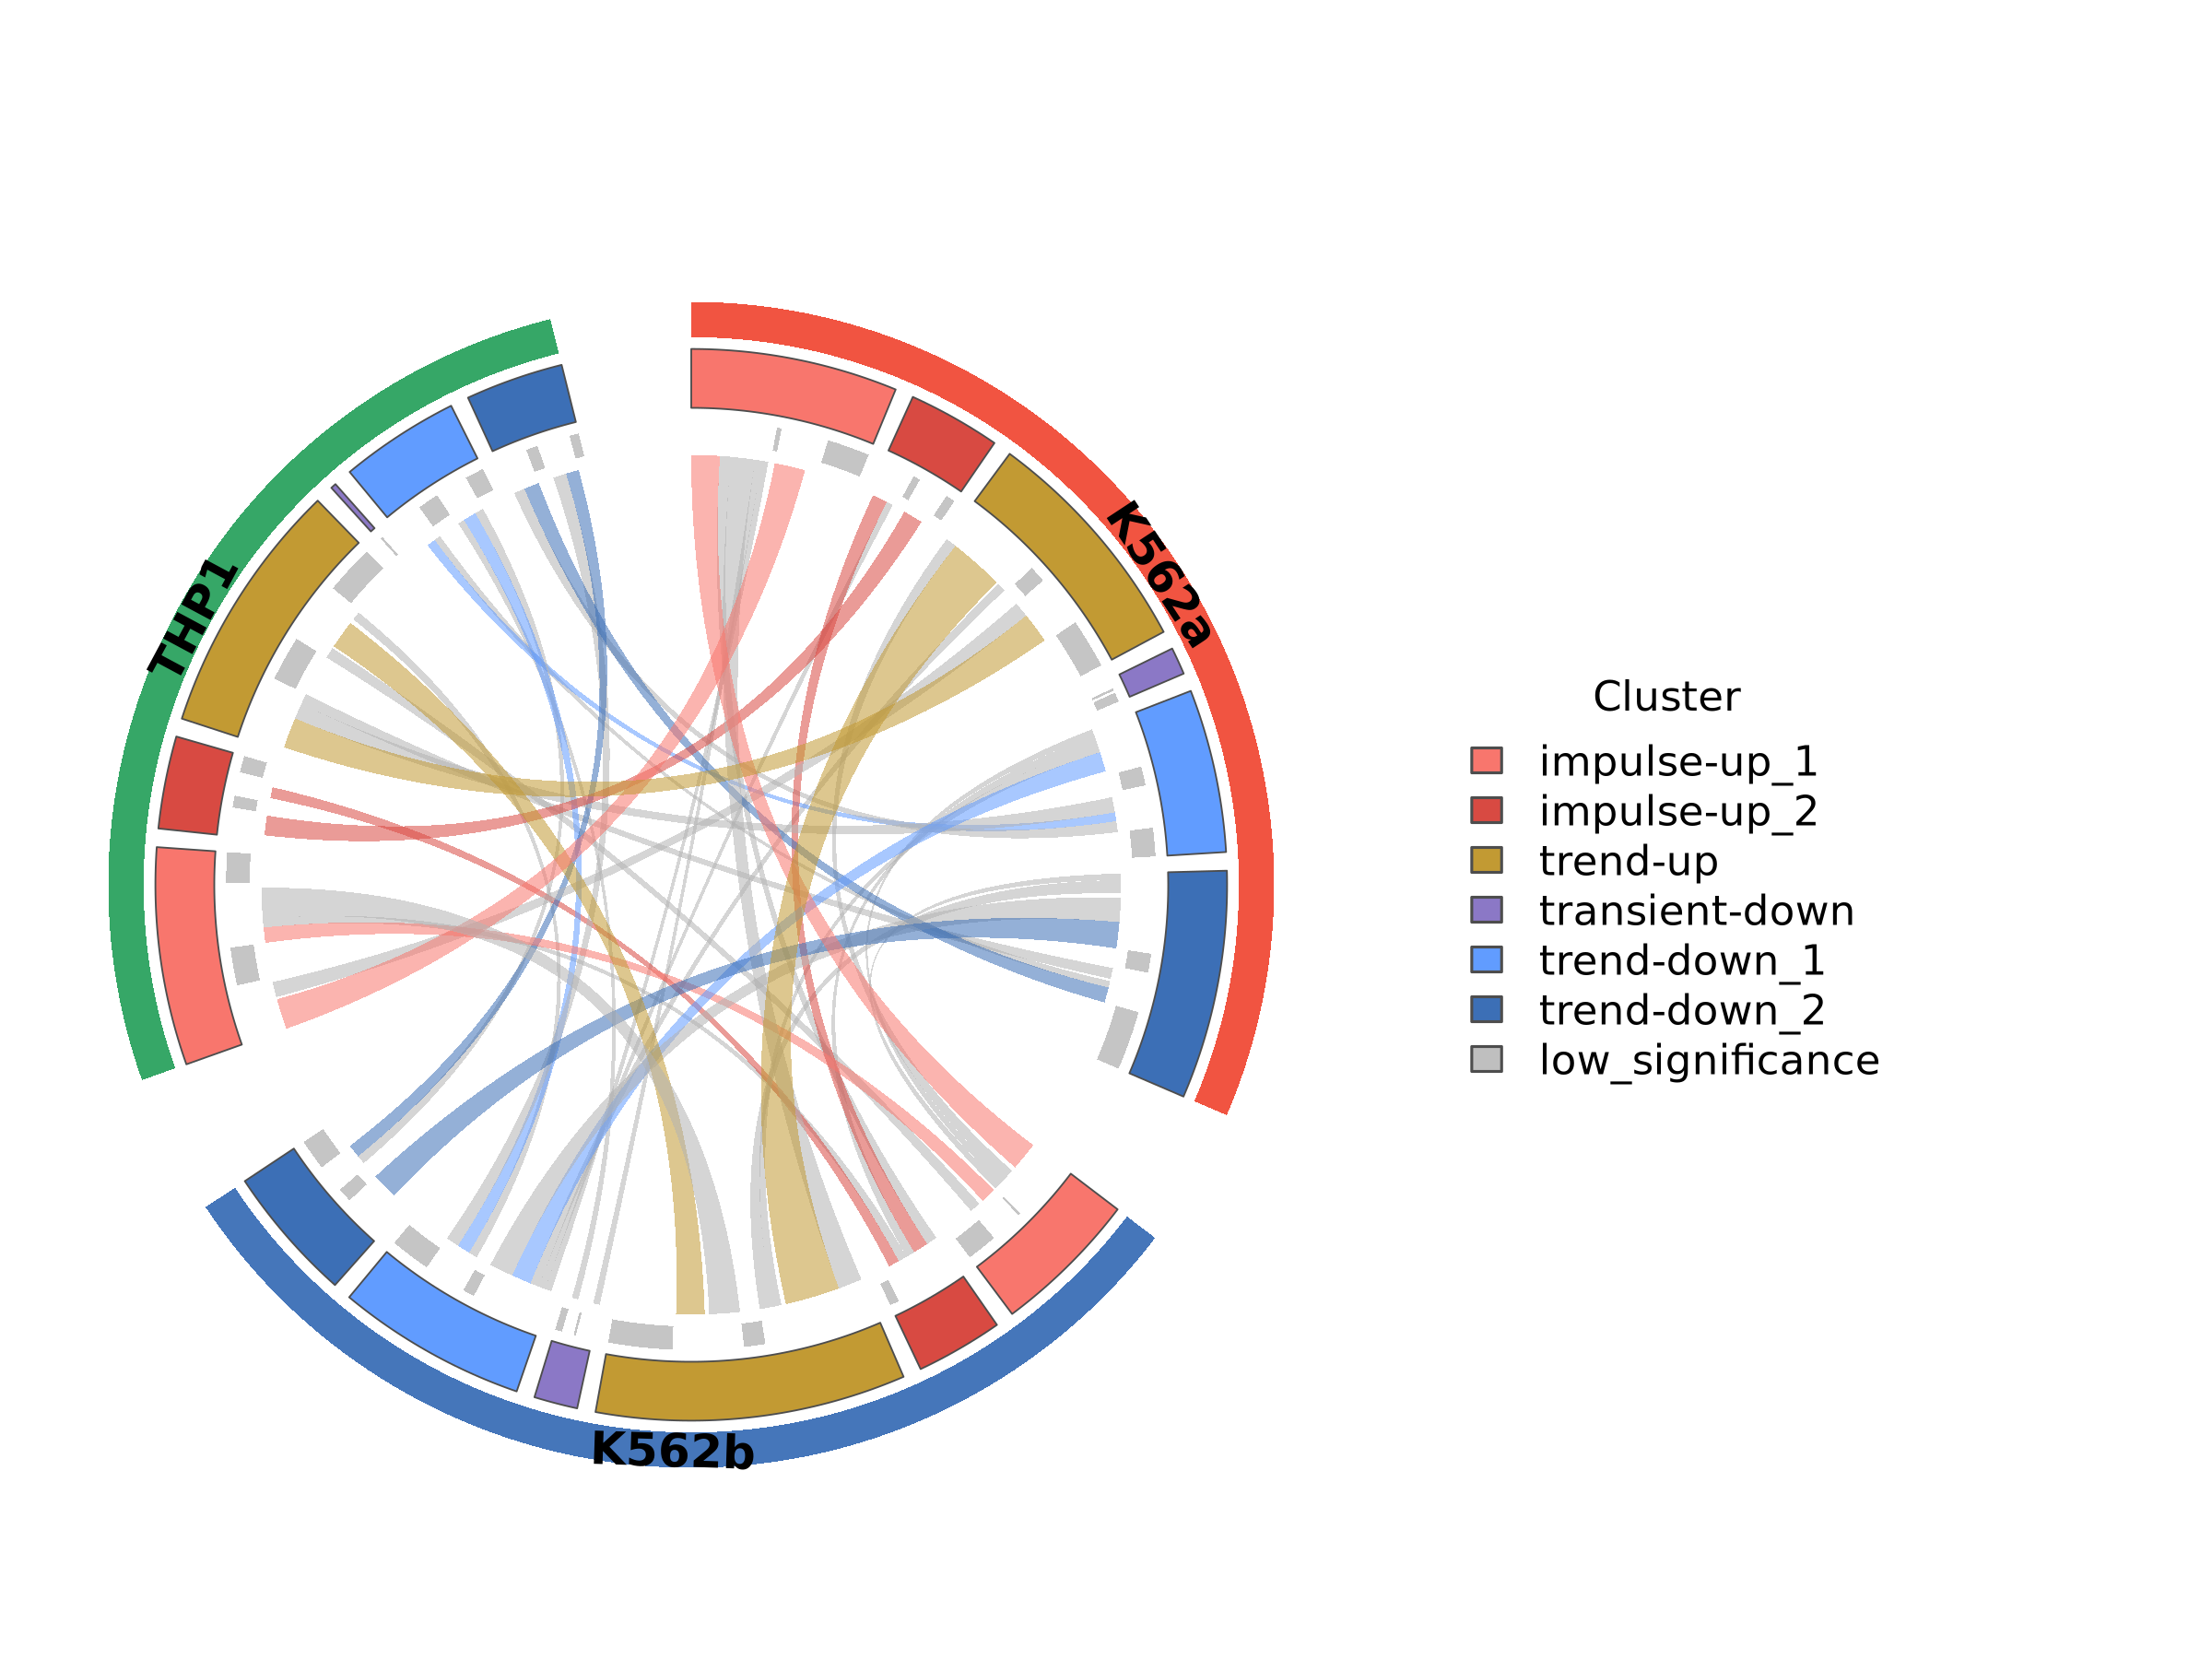

In [23]:
cp.pl.mode_chord(
    responsive,
    contexts=["K562a", "K562b", "THP1"],
    context_colors={"K562b": "#3b6fb6", "K562a": "#f04b37", "THP1": "#2ca25f"},
    top_k=100,
    min_flow=3,
    output=PLOT_DIR / "mode_reassignment_chord.svg",
)

## Representative genes per mode pair

Rows: broad mode in K562 + TNF-alpha; columns: broad mode in THP-1 + LPS. Each panel shows the gene with the highest K562a Wald statistic among genes in that pair of modes, as fitted tradeSeq curves of both contexts (blue K562a, black THP1). Genes in `exclude_genes` are used only when no other gene is available.

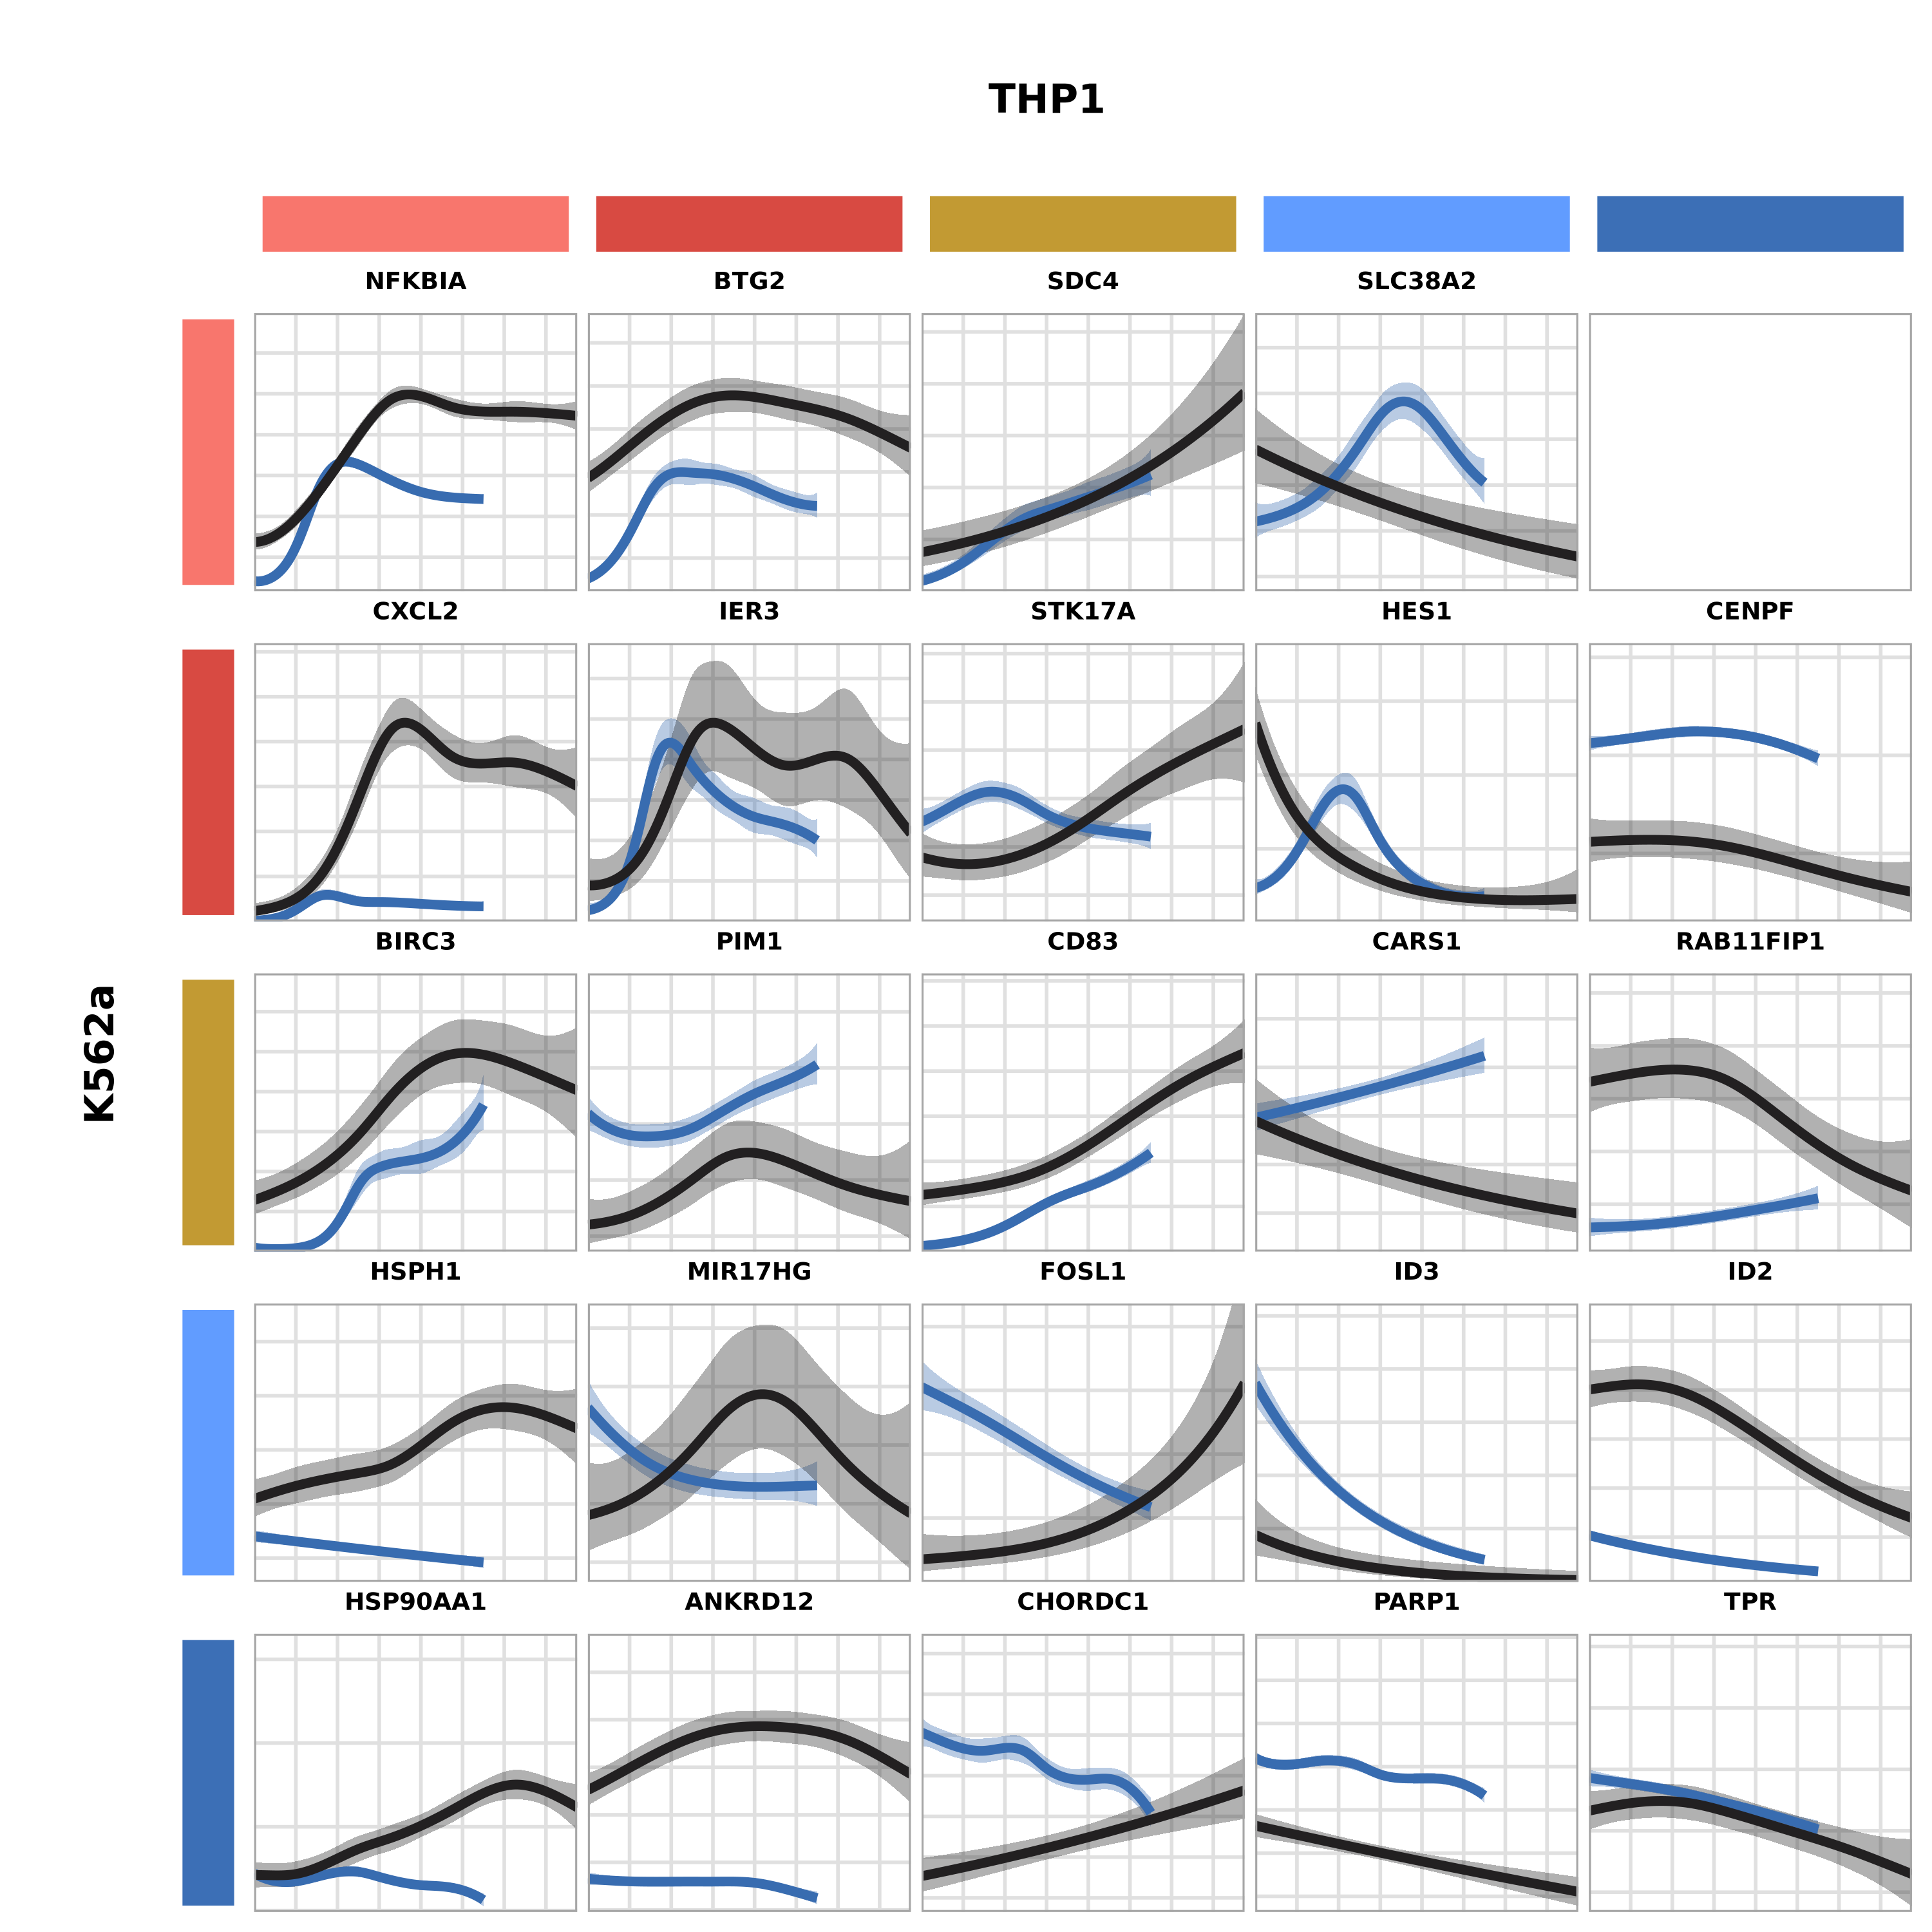

,row_cluster,col_cluster,gene,n_candidates_qpass
0,impulse-up_1,impulse-up_1,NFKBIA,19
1,impulse-up_1,impulse-up_2,BTG2,7
2,impulse-up_1,trend-up,SDC4,9
3,impulse-up_1,trend-down_1,SLC38A2,7
4,impulse-up_1,trend-down_2,NA_character_,0
5,impulse-up_2,impulse-up_1,CXCL2,2
6,impulse-up_2,impulse-up_2,IER3,11
7,impulse-up_2,trend-up,STK17A,5
8,impulse-up_2,trend-down_1,HES1,15
9,impulse-up_2,trend-down_2,CENPF,9


In [24]:
pair_genes = cp.pl.cluster_pair_representative_genes(
    traj,
    {c: sce_dict[c] for c in ["K562a", "THP1"]},
    row_context="K562a",
    col_context="THP1",
    clusters=["impulse-up_1", "impulse-up_2", "trend-up", "trend-down_1", "trend-down_2"],
    colours={"THP1": "#222021", "K562a": "#386cb0"},
    exclude_genes=["LAMTOR2", "SEPTIN9", "AP1S1", "CORO1C", "CTSZ", "LBR", "ZFP69B", "TM9SF2", "CKS1B"],
    output=PLOT_DIR / "cluster_pair_representative_genes.svg",
)
display(pair_genes)
pair_genes.data[["row_cluster", "col_cluster", "gene", "n_candidates_qpass"]]

## Peak and onset times of impulse-up genes

Peak and onset times of the top 100 impulse-up genes (impulse-up_1 and impulse-up_2 together) of each context.

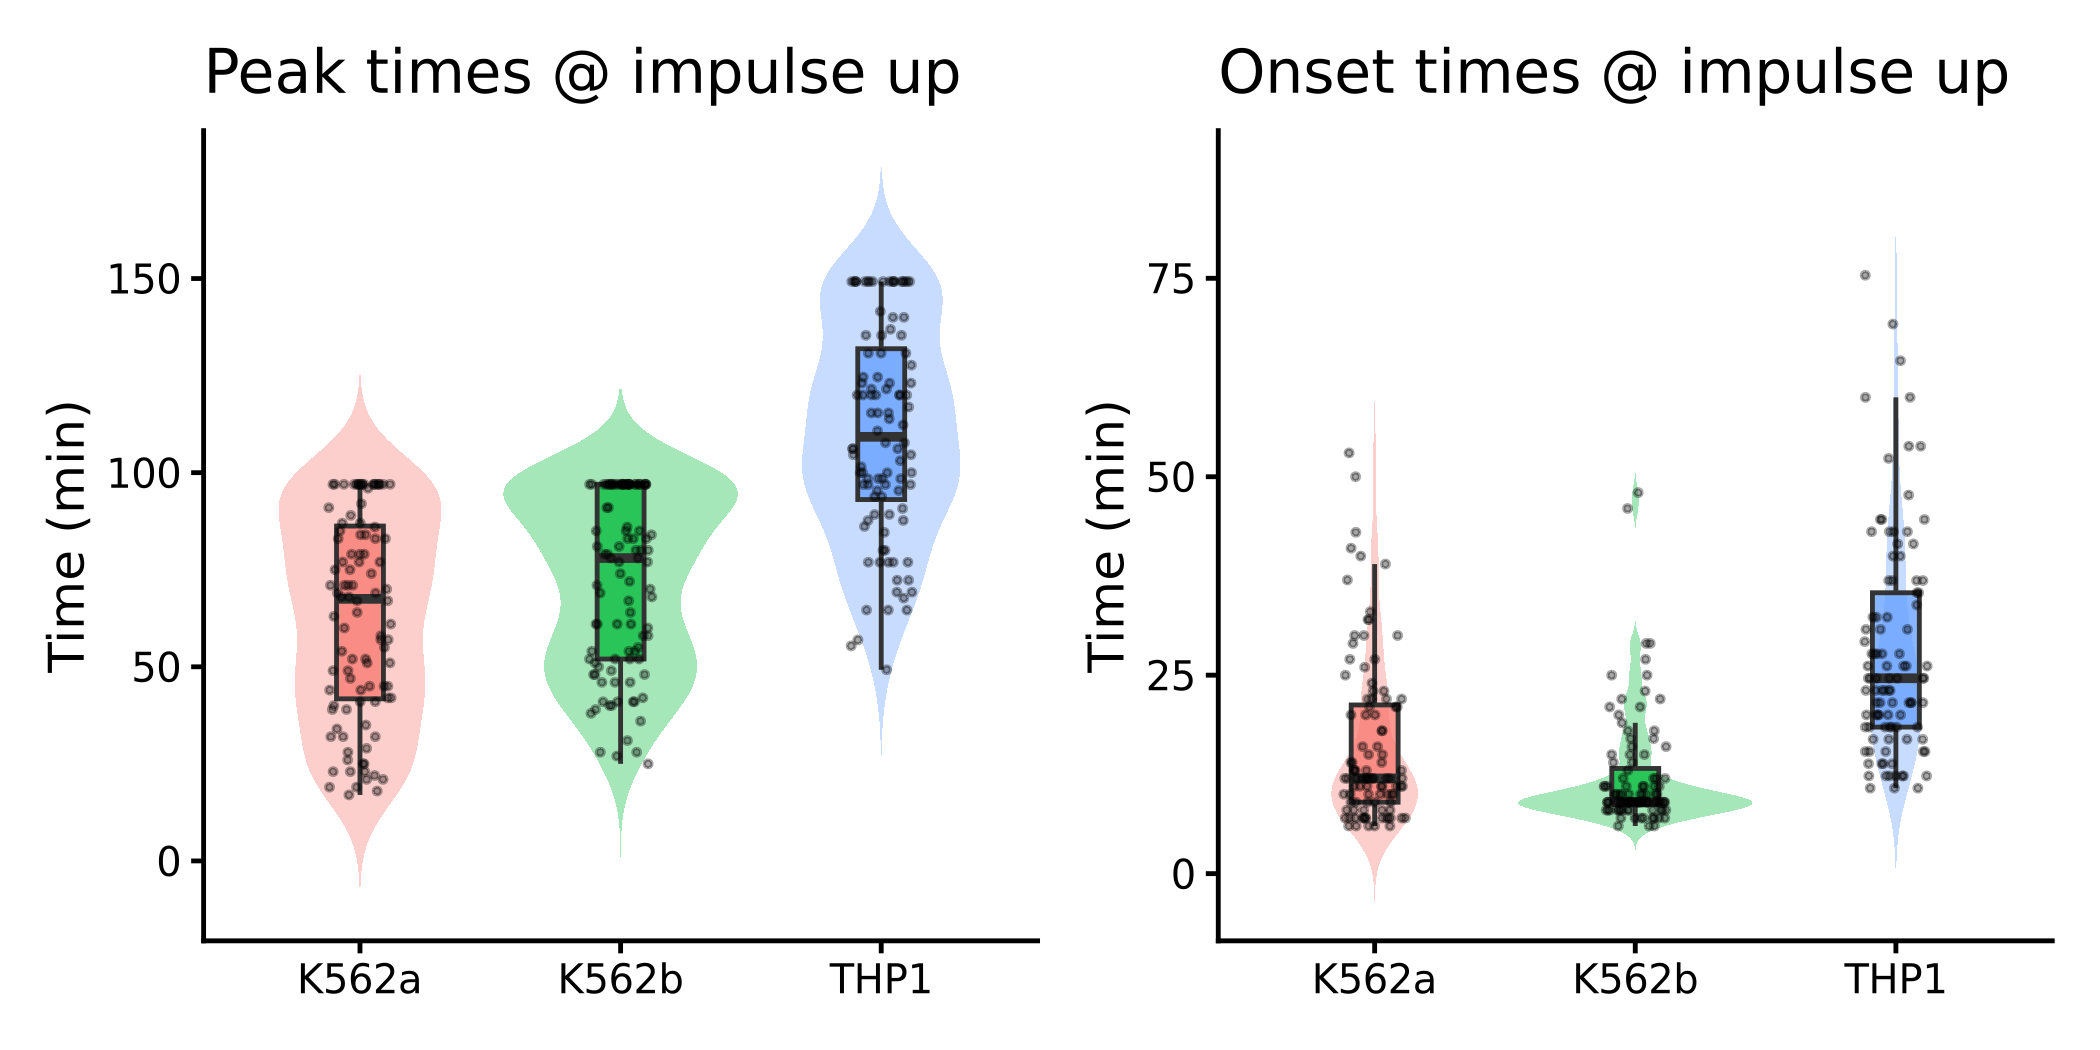

In [25]:
responsive.obs["broad_cluster2"] = responsive.obs["broad_cluster"].astype(str).replace(mode_groups)
cp.pl.cluster_violin(
    responsive,
    ["t_peak", "t_onset"],
    plot_titles=["Peak times @ impulse up", "Onset times @ impulse up"],
    y_title="Time (min)",
    cluster_col="broad_cluster2",
    cluster_use="impulse-up",
    contexts=["K562a", "K562b", "THP1"],
    top_k=100,
    output=PLOT_DIR / "impulse_up_peak_onset_times.svg",
)